In [2]:
from pathlib import Path

db_path = Path(
    r"C:\Users\jenny\Documents\UCB-MFE-python-preprogram-2026-winter\Lectures\modeling\data\equities_top2000.duckdb"
)

print(db_path.exists())

True


In [3]:
import duckdb

con = duckdb.connect(str(db_path), read_only=True)

tables = con.execute("SHOW TABLES").df()
tables

,name
0,benchmark
1,calendar
2,dataset_metadata
3,dividends
4,fundamentals
5,prices
6,universe
7,universe_candidates
8,universe_membership
9,universe_rebalances


In [4]:
for table in ["prices", "fundamentals", "universe_membership", "benchmark"]:
    print(f"\n--- {table} ---")
    print(con.execute(f"DESCRIBE {table}").df().to_string(index=False))


--- prices ---
column_name column_type null  key default extra
     symbol     VARCHAR  YES None    None  None
       date        DATE  YES None    None  None
       open      DOUBLE  YES None    None  None
       high      DOUBLE  YES None    None  None
        low      DOUBLE  YES None    None  None
      close      DOUBLE  YES None    None  None
  adj_close      DOUBLE  YES None    None  None
     volume      BIGINT  YES None    None  None
     source     VARCHAR  YES None    None  None

--- fundamentals ---
              column_name column_type null  key default extra
                   symbol     VARCHAR  YES None    None  None
              fiscal_date        DATE  YES None    None  None
                   period     VARCHAR  YES None    None  None
              filing_date        DATE  YES None    None  None
                  revenue      DOUBLE  YES None    None  None
             gross_profit      DOUBLE  YES None    None  None
         operating_income      DOUBLE  YES None 

In [5]:
# Check price history coverage: date range, total observations, and number of stocks
display(con.execute("""
    SELECT MIN(date) AS first_date,
           MAX(date) AS last_date,
           COUNT(*) AS rows,
           COUNT(DISTINCT symbol) AS symbols
    FROM prices
""").df())

# Check financial statement coverage using filing dates to track data availability
display(con.execute("""
    SELECT MIN(filing_date) AS first_filing_date,
           MAX(filing_date) AS last_filing_date,
           COUNT(*) AS rows,
           COUNT(DISTINCT symbol) AS symbols
    FROM fundamentals
""").df())

# Check when stocks entered the investable universe and how many stocks are included
display(con.execute("""
    SELECT MIN(effective_start) AS first_date,
           MAX(effective_start) AS last_date,
           COUNT(*) AS rows,
           COUNT(DISTINCT symbol) AS symbols
    FROM universe_membership
""").df())

# Check benchmark history coverage and confirm the number of benchmark symbols
display(con.execute("""
    SELECT MIN(date) AS first_date,
           MAX(date) AS last_date,
           COUNT(*) AS rows,
           COUNT(DISTINCT symbol) AS symbols
    FROM benchmark
""").df())

,first_date,last_date,rows,symbols
0,2000-01-03,2026-09-30,15839788,3849


,first_filing_date,last_filing_date,rows,symbols
0,2000-01-01,2026-09-30,284198,3849


,first_date,last_date,rows,symbols
0,2000-01-03,2026-07-01,195970,3849


,first_date,last_date,rows,symbols
0,2000-01-03,2026-09-30,6726,1


In [6]:
# Inspect sample financial statement records and available fundamental fields
print("FUNDAMENTALS")
display(con.execute("""
    SELECT symbol, fiscal_date, filing_date, period,
           revenue, gross_profit, net_income,
           total_equity, market_cap
    FROM fundamentals
    LIMIT 10
""").df())

# Inspect quarterly stock universe membership and selection information
print("UNIVERSE MEMBERSHIP")
display(con.execute("""
    SELECT *
    FROM universe_membership
    LIMIT 10
""").df())

# Identify the benchmark symbol and inspect its price records
print("BENCHMARK")
display(con.execute("""
    SELECT *
    FROM benchmark
    LIMIT 10
""").df())

FUNDAMENTALS


,symbol,fiscal_date,filing_date,period,revenue,gross_profit,net_income,total_equity,market_cap
0,A,2000-01-31,2000-03-15,quarter,2.246000e+09,1.086000e+09,131000000.0,4.486000e+09,NaN
1,A,2000-04-30,2000-06-12,quarter,2.485000e+09,7.480000e+08,166000000.0,4.642000e+09,NaN
2,A,2000-07-31,2000-09-01,quarter,2.670000e+09,8.250000e+08,155000000.0,4.902000e+09,NaN
3,A,2000-10-31,2001-01-17,quarter,3.372000e+09,1.640000e+09,305000000.0,5.265000e+09,NaN
4,A,2001-01-31,2001-03-19,quarter,2.841000e+09,1.392000e+09,154000000.0,5.541000e+09,NaN
5,A,2001-04-30,2001-06-14,quarter,2.382000e+09,9.760000e+08,102000000.0,5.616000e+09,NaN
6,A,2001-07-31,2001-09-14,quarter,1.806000e+09,6.600000e+08,-225000000.0,5.487000e+09,NaN
7,A,2001-10-31,2002-01-22,quarter,1.367000e+09,2.020000e+08,137000000.0,5.659000e+09,NaN
8,A,2002-01-31,2002-03-06,quarter,1.426000e+09,5.480000e+08,-315000000.0,5.395000e+09,NaN
9,A,2002-04-30,2002-06-05,quarter,1.457000e+09,6.030000e+08,-253000000.0,5.128000e+09,NaN


UNIVERSE MEMBERSHIP


,quarter_start,quarter_end,selection_date,effective_start,symbol,selection_close,shares_fiscal_date,shares_filing_date,shares_available_date,selection_shares,market_cap_proxy,universe_rank
0,2000-01-01,2000-03-31,1999-12-31,2000-01-03,SEEL,71243520.00,1999-09-30,1999-11-12,1999-11-13,1.000000e+04,7.124352e+11,1
1,2000-01-01,2000-03-31,1999-12-31,2000-01-03,MSFT,58.38,1999-09-30,1999-11-05,1999-11-06,1.105400e+10,6.453325e+11,2
2,2000-01-01,2000-03-31,1999-12-31,2000-01-03,CSCO,53.56,1999-10-30,1999-12-14,1999-12-15,7.288000e+09,3.903453e+11,3
3,2000-01-01,2000-03-31,1999-12-31,2000-01-03,WMT,23.04,1999-10-31,1999-12-15,1999-12-16,1.342500e+10,3.093120e+11,4
4,2000-01-01,2000-03-31,1999-12-31,2000-01-03,GE,246.85,1999-09-30,1999-10-26,1999-10-27,1.249875e+09,3.085316e+11,5
5,2000-01-01,2000-03-31,1999-12-31,2000-01-03,INTC,41.16,1999-09-25,1999-11-09,1999-11-10,6.943000e+09,2.857739e+11,6
6,2000-01-01,2000-03-31,1999-12-31,2000-01-03,XOM,40.28,1999-09-30,1999-11-12,1999-11-13,4.912000e+09,1.978554e+11,7
7,2000-01-01,2000-03-31,1999-12-31,2000-01-03,PFE,30.75,1999-10-03,1999-11-15,1999-11-16,6.322000e+09,1.944015e+11,8
8,2000-01-01,2000-03-31,1999-12-31,2000-01-03,IBM,103.04,1999-09-30,1999-11-12,1999-11-13,1.869600e+09,1.926436e+11,9
9,2000-01-01,2000-03-31,1999-12-31,2000-01-03,C,400.85,1999-09-30,1999-11-12,1999-11-13,4.586930e+08,1.838671e+11,10


BENCHMARK


,symbol,date,close,adj_close,source
0,^SP500TR,2000-01-03,2002.11,2002.11,fmp
1,^SP500TR,2000-01-04,1925.41,1925.41,fmp
2,^SP500TR,2000-01-05,1929.28,1929.28,fmp
3,^SP500TR,2000-01-06,1931.51,1931.51,fmp
4,^SP500TR,2000-01-07,1983.83,1983.83,fmp
5,^SP500TR,2000-01-10,2006.07,2006.07,fmp
6,^SP500TR,2000-01-11,1979.92,1979.92,fmp
7,^SP500TR,2000-01-12,1971.36,1971.36,fmp
8,^SP500TR,2000-01-13,1995.35,1995.35,fmp
9,^SP500TR,2000-01-14,2016.64,2016.64,fmp


In [7]:
# Check how many quarterly and annual fundamental records are available
display(con.execute("""
    SELECT period, COUNT(*) AS rows,
           COUNT(DISTINCT symbol) AS symbols
    FROM fundamentals
    GROUP BY period
    ORDER BY period
""").df())

# Check missing values in important fundamental fields
display(con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(market_cap) AS market_cap_available,
        COUNT(total_equity) AS equity_available,
        COUNT(net_income) AS net_income_available,
        COUNT(gross_profit) AS gross_profit_available,
        COUNT(filing_date) AS filing_date_available
    FROM fundamentals
""").df())

# Check how often the investable universe is updated
display(con.execute("""
    SELECT quarter_start, COUNT(*) AS stock_count,
           MIN(effective_start) AS effective_start,
           MAX(effective_start) AS latest_effective_start
    FROM universe_membership
    GROUP BY quarter_start
    ORDER BY quarter_start
    LIMIT 12
""").df())

,period,rows,symbols
0,annual,6,5
1,inception,1,1
2,quarter,284188,3849
3,transition,3,3


,total_rows,market_cap_available,equity_available,net_income_available,gross_profit_available,filing_date_available
0,284198,10847,278223,284198,284143,284198


,quarter_start,stock_count,effective_start,latest_effective_start
0,2000-01-01,1206,2000-01-03,2000-01-03
1,2000-04-01,1220,2000-04-03,2000-04-03
2,2000-07-01,1248,2000-07-03,2000-07-03
3,2000-10-01,1265,2000-10-02,2000-10-02
4,2001-01-01,1281,2001-01-02,2001-01-02
5,2001-04-01,1285,2001-04-02,2001-04-02
6,2001-07-01,1303,2001-07-02,2001-07-02
7,2001-10-01,1319,2001-10-01,2001-10-01
8,2002-01-01,1323,2002-01-02,2002-01-02
9,2002-04-01,1336,2002-04-01,2002-04-01


In [8]:
# Check availability of additional financial fields for constructing factors
display(con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(shares_outstanding) AS shares_available,
        COUNT(total_assets) AS assets_available,
        COUNT(total_equity) AS equity_available,
        COUNT(total_debt) AS debt_available,
        COUNT(revenue) AS revenue_available,
        COUNT(gross_profit) AS gross_profit_available,
        COUNT(net_income) AS net_income_available,
        COUNT(operating_cash_flow) AS cash_flow_available
    FROM fundamentals
""").df())

# Inspect sample records containing shares outstanding
display(con.execute("""
    SELECT symbol, fiscal_date, filing_date,
           shares_outstanding, total_assets,
           total_equity, net_income
    FROM fundamentals
    WHERE shares_outstanding IS NOT NULL
    LIMIT 10
""").df())

,total_rows,shares_available,assets_available,equity_available,debt_available,revenue_available,gross_profit_available,net_income_available,cash_flow_available
0,284198,284118,278225,278223,278161,284193,284143,284198,280826


,symbol,fiscal_date,filing_date,shares_outstanding,total_assets,total_equity,net_income
0,A,2000-01-31,2000-03-15,440000000.0,7.107000e+09,4.486000e+09,131000000.0
1,A,2000-04-30,2000-06-12,457000000.0,7.321000e+09,4.642000e+09,166000000.0
2,A,2000-07-31,2000-09-01,461000000.0,7.827000e+09,4.902000e+09,155000000.0
3,A,2000-10-31,2001-01-17,466000000.0,8.330000e+09,5.265000e+09,305000000.0
4,A,2001-01-31,2001-03-19,466000000.0,9.208000e+09,5.541000e+09,154000000.0
5,A,2001-04-30,2001-06-14,461000000.0,9.080000e+09,5.616000e+09,102000000.0
6,A,2001-07-31,2001-09-14,459000000.0,8.622000e+09,5.487000e+09,-225000000.0
7,A,2001-10-31,2002-01-22,463000000.0,7.986000e+09,5.659000e+09,137000000.0
8,A,2002-01-31,2002-03-06,463000000.0,8.558000e+09,5.395000e+09,-315000000.0
9,A,2002-04-30,2002-06-05,464000000.0,8.238000e+09,5.128000e+09,-253000000.0


In [12]:

### Data Quality and Portfolio Diversification RulesDiversification:** The strategy will initially hold 30 stocks in an equal-weighted portfolio, targeting approximately 3.33% per stock. Individual stock exposure will be capped at 5%, and sector exposure at 20%. The portfolio will be long-only, unleveraged, and rebalanced monthly, with each position held for 90 calendar days. If too few stocks pass the data-quality screen, I will reduce the number of holdings rather than relax the quality standards.


In [10]:
## 2. Data Preparation and Feature Engineering

In [17]:
# Load the core price, universe, and fundamental data into pandas
prices = con.execute("""
    SELECT symbol, date, adj_close, volume
    FROM prices
    WHERE date BETWEEN '2009-01-01' AND '2026-09-30'
      AND adj_close > 0
    ORDER BY symbol, date
""").df()

universe = con.execute("""
    SELECT symbol, sector
    FROM universe
""").df()

membership = con.execute("""
    SELECT symbol, effective_start, quarter_end
    FROM universe_membership
""").df()

fundamentals = con.execute("""
    SELECT *
    FROM fundamentals
    ORDER BY symbol, filing_date
""").df()

print("Prices:", prices.shape)
print("Universe:", universe.shape)
print("Membership:", membership.shape)
print("Fundamentals:", fundamentals.shape)

Prices: (12065479, 4)
Universe: (3849, 2)
Membership: (195970, 3)
Fundamentals: (284198, 46)


In [18]:
# Import pandas and NumPy
import pandas as pd
import numpy as np

print(pd.__version__)

2.3.3


In [19]:
# Create the first trading day of each month as the monthly signal date
prices["date"] = pd.to_datetime(prices["date"])

monthly_dates = (
    prices[prices["date"].between("2010-01-01", "2015-12-31")]
    .groupby(prices["date"].dt.to_period("M"))["date"]
    .min()
    .reset_index(drop=True)
)

# Create a table of monthly signal dates
monthly_dates = pd.DataFrame({
    "investment_month": monthly_dates.dt.to_period("M"),
    "signal_date": monthly_dates
})

# Display the first and last signal dates
display(monthly_dates.head())
display(monthly_dates.tail())

print("Number of investment months:", len(monthly_dates))

,investment_month,signal_date
0,2010-01,2010-01-04
1,2010-02,2010-02-01
2,2010-03,2010-03-01
3,2010-04,2010-04-01
4,2010-05,2010-05-03


,investment_month,signal_date
67,2015-08,2015-08-03
68,2015-09,2015-09-01
69,2015-10,2015-10-01
70,2015-11,2015-11-02
71,2015-12,2015-12-01


Number of investment months: 72


In [21]:
# Data handling
import pandas as pd
import numpy as np

# Database
import duckdb

# Visualization
import matplotlib.pyplot as plt

# Machine learning: preprocessing and models
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Model evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Portfolio performance evaluation
from scipy.stats import spearmanr

# Date and warning utilities
from datetime import timedelta
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


In [22]:
# Convert membership dates to pandas datetime
membership["effective_start"] = pd.to_datetime(membership["effective_start"])
membership["quarter_end"] = pd.to_datetime(membership["quarter_end"])

# Identify eligible stocks for each monthly signal date
monthly_universe = []

for row in monthly_dates.itertuples(index=False):
    signal = row.signal_date

    eligible = membership[
        (membership["effective_start"] <= signal) &
        (
            membership["quarter_end"].isna() |
            (membership["quarter_end"] >= signal)
        )
    ][["symbol"]].copy()

    eligible["investment_month"] = row.investment_month
    eligible["signal_date"] = signal

    monthly_universe.append(eligible)

# Combine monthly stock selections and attach sector classifications
monthly_universe = pd.concat(monthly_universe, ignore_index=True)
monthly_universe = monthly_universe.merge(
    universe,
    on="symbol",
    how="left"
)

# Review the investable universe
display(monthly_universe.head())
print("Total stock-month observations:", len(monthly_universe))
print("Unique stocks:", monthly_universe["symbol"].nunique())
print("Months:", monthly_universe["investment_month"].nunique())

,symbol,investment_month,signal_date,sector
0,TSYS,2010-01,2010-01-04,Communication Services
1,APDN,2010-01,2010-01-04,Healthcare
2,XOM,2010-01,2010-01-04,Energy
3,PEGY,2010-01,2010-01-04,Energy
4,MSFT,2010-01,2010-01-04,Technology


Total stock-month observations: 142857
Unique stocks: 2482
Months: 72


In [23]:
# Sort prices chronologically within each stock
prices = prices.sort_values(["symbol", "date"]).copy()

# Calculate historical adjusted prices using trading-day lags
price_features = prices[["symbol", "date", "adj_close"]].copy()

for name, lag in {
    "price_1m": 21,
    "price_3m": 63,
    "price_6m": 126,
    "price_12m": 252
}.items():
    price_features[name] = (
        price_features.groupby("symbol")["adj_close"].shift(lag)
    )

# Match each stock-month observation with its latest available price
monthly_universe = monthly_universe.sort_values(
    ["signal_date", "symbol"]
)

price_features = price_features.sort_values(
    ["date", "symbol"]
)

monthly_data = pd.merge_asof(
    monthly_universe,
    price_features,
    left_on="signal_date",
    right_on="date",
    by="symbol",
    direction="backward",
    tolerance=pd.Timedelta(days=7)
)

# Calculate momentum returns
monthly_data["momentum_1m"] = (
    monthly_data["adj_close"] / monthly_data["price_1m"] - 1
)
monthly_data["momentum_3m"] = (
    monthly_data["adj_close"] / monthly_data["price_3m"] - 1
)
monthly_data["momentum_6m"] = (
    monthly_data["adj_close"] / monthly_data["price_6m"] - 1
)
monthly_data["momentum_12m"] = (
    monthly_data["adj_close"] / monthly_data["price_12m"] - 1
)

# Review the calculated features
display(monthly_data[
    ["symbol", "signal_date", "sector",
     "momentum_1m", "momentum_3m",
     "momentum_6m", "momentum_12m"]
].head(10))

print("Total observations:", len(monthly_data))
print("Observations with all four momentum features:",
      monthly_data[["momentum_1m", "momentum_3m",
                    "momentum_6m", "momentum_12m"]].dropna().shape[0])

,symbol,signal_date,sector,momentum_1m,momentum_3m,momentum_6m,momentum_12m
0,A,2010-01-04,Healthcare,0.061093,0.189904,0.600647,0.927945
1,AAIC,2010-01-04,Real Estate,0.165681,0.751112,1.129731,2.581820
2,AAL,2010-01-04,Industrials,0.201511,0.106729,1.012657,-0.431466
3,AAN,2010-01-04,Industrials,0.081680,0.055008,-0.036383,NaN
4,AAON,2010-01-04,Industrials,0.026627,0.061162,0.005797,-0.025281
5,AAP,2010-01-04,Consumer Cyclical,-0.004305,0.079005,-0.044089,0.189643
6,AAPL,2010-01-04,Technology,0.088435,0.157324,0.542169,1.352941
7,AAWW,2010-01-04,Industrials,0.210010,0.305983,0.729289,0.908092
8,ABC,2010-01-04,Healthcare,0.075285,0.235629,0.505548,0.515003
9,ABCB,2010-01-04,Financial Services,0.060000,0.040917,0.193246,-0.343653


Total observations: 142857
Observations with all four momentum features: 138008


In [30]:

# Match each stock-month observation with its latest publicly filed financial statements

fundamentals["filing_date"] = pd.to_datetime(
    fundamentals["filing_date"]
).astype("datetime64[ns]")

monthly_data["signal_date"] = pd.to_datetime(
    monthly_data["signal_date"]
).astype("datetime64[ns]")

fundamentals["symbol"] = fundamentals["symbol"].astype(str)
monthly_data["symbol"] = monthly_data["symbol"].astype(str)

fundamental_features = fundamentals.dropna(
    subset=["filing_date"]
).copy()

fundamental_features = fundamental_features.sort_values(
    ["filing_date", "symbol"]
)

monthly_data = monthly_data.sort_values(
    ["signal_date", "symbol"]
)

monthly_data = pd.merge_asof(
    monthly_data,
    fundamental_features[
        [
            "symbol", "filing_date", "shares_outstanding",
            "total_assets", "total_equity", "total_debt",
            "revenue", "gross_profit", "net_income",
            "operating_cash_flow"
        ]
    ].sort_values(["filing_date", "symbol"]),
    left_on="signal_date",
    right_on="filing_date",
    by="symbol",
    direction="backward"
)

# Calculate market capitalization using signal-date price and reported shares
monthly_data["market_cap"] = (
    monthly_data["adj_close"] * monthly_data["shares_outstanding"]
)

# VALUE FACTORS
monthly_data["book_to_market"] = (
    monthly_data["total_equity"] / monthly_data["market_cap"]
)

monthly_data["earnings_yield"] = (
    monthly_data["net_income"] / monthly_data["market_cap"]
)

monthly_data["sales_to_market"] = (
    monthly_data["revenue"] / monthly_data["market_cap"]
)

monthly_data["cash_flow_to_market"] = (
    monthly_data["operating_cash_flow"] / monthly_data["market_cap"]
)

# QUALITY FACTORS
monthly_data["roe"] = (
    monthly_data["net_income"] / monthly_data["total_equity"]
)

monthly_data["roa"] = (
    monthly_data["net_income"] / monthly_data["total_assets"]
)

monthly_data["gross_profitability"] = (
    monthly_data["gross_profit"] / monthly_data["total_assets"]
)

monthly_data["operating_cash_flow_to_assets"] = (
    monthly_data["operating_cash_flow"] / monthly_data["total_assets"]
)

monthly_data["net_margin"] = (
    monthly_data["net_income"] / monthly_data["revenue"]
)

monthly_data["debt_to_assets"] = (
    monthly_data["total_debt"] / monthly_data["total_assets"]
)

# Review fundamental factor availability
fundamental_factors = [
    "book_to_market",
    "earnings_yield",
    "sales_to_market",
    "cash_flow_to_market",
    "roe",
    "roa",
    "gross_profitability",
    "operating_cash_flow_to_assets",
    "net_margin",
    "debt_to_assets"
]

display(
    monthly_data[fundamental_factors]
    .notna()
    .sum()
    .rename("available_observations")
    .to_frame()
)


,available_observations
book_to_market,140476
earnings_yield,140675
sales_to_market,140669
cash_flow_to_market,140182
roe,140477
roa,140484
gross_profitability,140474
operating_cash_flow_to_assets,140068
net_margin,140589
debt_to_assets,140470


In [31]:

# Add 12-month momentum excluding the most recent month

monthly_data["momentum_12m_1m"] = (
    monthly_data["price_1m"] / monthly_data["price_12m"] - 1
)

momentum_factors = [
    "momentum_1m",
    "momentum_3m",
    "momentum_6m",
    "momentum_12m",
    "momentum_12m_1m"
]

display(monthly_data[momentum_factors].head())


,momentum_1m,momentum_3m,momentum_6m,momentum_12m,momentum_12m_1m
0,0.061093,0.189904,0.600647,0.927945,0.816943
1,0.165681,0.751112,1.129731,2.581820,2.072728
2,0.201511,0.106729,1.012657,-0.431466,-0.526818
3,0.081680,0.055008,-0.036383,NaN,NaN
4,0.026627,0.061162,0.005797,-0.025281,-0.050562


In [32]:

# Calculate annualized historical volatility from daily adjusted-price returns

prices = prices.sort_values(["symbol", "date"]).copy()

prices["daily_return"] = (
    prices.groupby("symbol")["adj_close"].pct_change()
)

for window in [21, 63, 126]:
    prices[f"volatility_{window}d"] = (
        prices.groupby("symbol")["daily_return"]
        .transform(
            lambda x: x.rolling(
                window,
                min_periods=int(window * 0.8)
            ).std() * np.sqrt(252)
        )
    )

# Match historical volatility to each stock's monthly signal date
volatility_features = prices[
    ["symbol", "date", "volatility_21d",
     "volatility_63d", "volatility_126d"]
].copy()

volatility_features["date"] = pd.to_datetime(
    volatility_features["date"]
).astype("datetime64[ns]")

monthly_data = monthly_data.sort_values("signal_date")
volatility_features = volatility_features.sort_values("date")

monthly_data = pd.merge_asof(
    monthly_data,
    volatility_features,
    left_on="signal_date",
    right_on="date",
    by="symbol",
    direction="backward",
    tolerance=pd.Timedelta(days=7)
)

# Review low-volatility factor availability
volatility_factors = [
    "volatility_21d",
    "volatility_63d",
    "volatility_126d"
]

display(
    monthly_data[volatility_factors]
    .notna()
    .sum()
    .rename("available_observations")
    .to_frame()
)


,available_observations
volatility_21d,140649
volatility_63d,140398
volatility_126d,139407


In [33]:

# Combine all 18 factor features for data-quality checks

factor_columns = [
    "book_to_market",
    "earnings_yield",
    "sales_to_market",
    "cash_flow_to_market",
    "momentum_1m",
    "momentum_3m",
    "momentum_6m",
    "momentum_12m",
    "momentum_12m_1m",
    "roe",
    "roa",
    "gross_profitability",
    "operating_cash_flow_to_assets",
    "net_margin",
    "debt_to_assets",
    "volatility_21d",
    "volatility_63d",
    "volatility_126d"
]

# Count missing and infinite values in each feature
factor_check = pd.DataFrame({
    "missing": monthly_data[factor_columns].isna().sum(),
    "infinite": np.isinf(
        monthly_data[factor_columns]
    ).sum(),
    "available": monthly_data[factor_columns].notna().sum()
})

display(factor_check)

# Review the distribution of each factor
display(
    monthly_data[factor_columns]
    .describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])
    .T
    .round(4)
)


,missing,infinite,available
book_to_market,215,75,140476
earnings_yield,16,75,140675
sales_to_market,22,69,140669
cash_flow_to_market,509,75,140182
momentum_1m,52,0,140639
momentum_3m,502,0,140189
momentum_6m,1833,0,138858
momentum_12m,4713,0,135978
momentum_12m_1m,4713,0,135978
roe,214,61,140477


,count,mean,std,min,1%,5%,50%,95%,99%,max
book_to_market,140476.0,NaN,NaN,-inf,-0.4112,0.0122,0.5640,2.4189,5.9673,inf
earnings_yield,140675.0,NaN,NaN,-inf,-0.2990,-0.0556,0.0138,0.0596,0.1984,inf
sales_to_market,140669.0,NaN,NaN,-inf,0.0000,0.0065,0.1847,1.3000,4.2970,inf
cash_flow_to_market,140182.0,NaN,NaN,-inf,-0.3603,-0.0621,0.0234,0.1489,0.4290,inf
momentum_1m,140639.0,1.0585,288.6107,-1.0000,-0.2797,-0.1549,0.0134,0.1905,0.3674,96821.9955
momentum_3m,140189.0,1.1042,282.0473,-1.0000,-0.4378,-0.2500,0.0342,0.3583,0.7143,90496.7376
momentum_6m,138858.0,0.4484,105.7420,-1.0000,-0.5476,-0.3128,0.0710,0.5751,1.2000,39300.3100
momentum_12m,135978.0,1.1144,187.1378,-0.9937,-0.6461,-0.3710,0.1565,1.0675,2.5793,54627.5714
momentum_12m_1m,135978.0,1.9067,287.4375,-1.0000,-0.6268,-0.3612,0.1439,1.0036,2.4021,60330.8250
roe,140477.0,NaN,NaN,-inf,-0.9291,-0.1520,0.0240,0.1338,0.8574,inf


In [36]:
# Replace infinite factor values with missing values
monthly_data[factor_columns] = monthly_data[factor_columns].replace(
    [np.inf, -np.inf], np.nan
)

print("Total missing factor values:",
      monthly_data[factor_columns].isna().sum().sum())

Total missing factor values: 18759


In [38]:
# Prepare the 18 factor features for Ridge Regression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer

# Impute missing values and standardize the factor features
numeric = Pipeline([
    ("impute", SimpleImputer(
        strategy="median",
        add_indicator=True,
        keep_empty_features=True
    )),
    ("scale", StandardScaler())
])

# Apply preprocessing to the 18 factor columns
preprocessor = ColumnTransformer([
    ("factors", numeric, factor_columns)
], remainder="drop")

# Build the Ridge Regression model
ridge_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=100))
])

In [42]:
# Check the date coverage of the quarterly stock universe
membership["effective_start"] = pd.to_datetime(
    membership["effective_start"]
)
membership["quarter_end"] = pd.to_datetime(
    membership["quarter_end"]
)

print("Membership columns:")
print(membership.columns.tolist())

print("\nMembership date coverage:")
print("Earliest quarter:", membership["quarter_end"].min())
print("Latest quarter:", membership["quarter_end"].max())

print("\nQuarterly universe observations:")
print(
    membership.groupby("quarter_end")["symbol"]
    .nunique()
    .tail(10)
)

print("\nMonthly data date coverage:")
print("Earliest signal:", monthly_data["signal_date"].min())
print("Latest signal:", monthly_data["signal_date"].max())

Membership columns:
['symbol', 'effective_start', 'quarter_end']

Membership date coverage:
Earliest quarter: 2000-03-31 00:00:00
Latest quarter: 2026-09-30 00:00:00

Quarterly universe observations:
quarter_end
2024-06-30    2000
2024-09-30    2000
2024-12-31    2000
2025-03-31    2000
2025-06-30    2000
2025-09-30    2000
2025-12-31    2000
2026-03-31    2000
2026-06-30    2000
2026-09-30    2000
Name: symbol, dtype: int64

Monthly data date coverage:
Earliest signal: 2010-01-04 00:00:00
Latest signal: 2015-11-02 00:00:00


In [43]:
# Create monthly investment dates through September 2026

trading_dates = np.sort(
    pd.to_datetime(prices["date"]).dt.normalize().unique()
)

month_starts = pd.date_range(
    start="2010-01-01",
    end="2026-09-01",
    freq="MS"
)

monthly_dates = pd.DataFrame({
    "investment_month": range(len(month_starts)),
    "month_start": month_starts
})

# Find the first trading session on or after each month start
date_indices = np.searchsorted(
    trading_dates,
    monthly_dates["month_start"].values,
    side="left"
)

monthly_dates["signal_date"] = pd.NaT

valid_dates = date_indices < len(trading_dates)

monthly_dates.loc[valid_dates, "signal_date"] = pd.to_datetime(
    trading_dates[date_indices[valid_dates]]
)

monthly_dates = monthly_dates.dropna(
    subset=["signal_date"]
).reset_index(drop=True)

print("Monthly investment dates:", len(monthly_dates))
print("First signal date:", monthly_dates["signal_date"].min())
print("Last signal date:", monthly_dates["signal_date"].max())

Monthly investment dates: 201
First signal date: 2010-01-04 00:00:00
Last signal date: 2026-09-01 00:00:00


In [44]:
# Build the monthly stock candidate universe

membership_dates = membership.copy()
membership_dates["effective_start"] = pd.to_datetime(
    membership_dates["effective_start"]
).dt.normalize()

monthly_dates["signal_date"] = pd.to_datetime(
    monthly_dates["signal_date"]
).dt.normalize()

# Match each month to stocks belonging to its latest effective universe
monthly_universe = monthly_dates.merge(
    membership_dates,
    left_on="signal_date",
    right_on="effective_start",
    how="inner"
)

# Attach adjusted closing prices on each signal date
price_lookup = prices[["symbol", "date", "adj_close"]].copy()
price_lookup["date"] = pd.to_datetime(
    price_lookup["date"]
).dt.normalize()

monthly_universe = monthly_universe.merge(
    price_lookup,
    left_on=["symbol", "signal_date"],
    right_on=["symbol", "date"],
    how="left"
).drop(columns=["date"])

# Keep stocks with an available adjusted closing price
monthly_universe = monthly_universe.dropna(
    subset=["adj_close"]
).copy()

print("Monthly stock observations:", len(monthly_universe))
print("First signal date:", monthly_universe["signal_date"].min())
print("Last signal date:", monthly_universe["signal_date"].max())
print("Unique stocks:", monthly_universe["symbol"].nunique())

Monthly stock observations: 131512
First signal date: 2010-01-04 00:00:00
Last signal date: 2026-07-01 00:00:00
Unique stocks: 3834


In [45]:
# Match every monthly signal date to its active quarterly stock universe

monthly_universe = monthly_dates.merge(
    membership,
    how="cross"
)

monthly_universe = monthly_universe[
    (monthly_universe["signal_date"] >= monthly_universe["effective_start"]) &
    (monthly_universe["signal_date"] <= monthly_universe["quarter_end"])
].copy()

# Attach adjusted closing prices on each signal date
price_lookup = prices[["symbol", "date", "adj_close"]].copy()
price_lookup["date"] = pd.to_datetime(price_lookup["date"]).dt.normalize()

monthly_universe = monthly_universe.merge(
    price_lookup,
    left_on=["symbol", "signal_date"],
    right_on=["symbol", "date"],
    how="left"
).drop(columns=["date"])

monthly_universe = monthly_universe.dropna(subset=["adj_close"]).copy()

print("Monthly stock observations:", len(monthly_universe))
print("First signal date:", monthly_universe["signal_date"].min())
print("Last signal date:", monthly_universe["signal_date"].max())

Monthly stock observations: 395880
First signal date: 2010-01-04 00:00:00
Last signal date: 2026-09-01 00:00:00


In [46]:
# Calculate momentum and rolling volatility using historical adjusted prices

price_factors = prices[["symbol", "date", "adj_close"]].copy()
price_factors["date"] = pd.to_datetime(price_factors["date"]).dt.normalize()
price_factors = price_factors.sort_values(["symbol", "date"]).reset_index(drop=True)

# Calculate daily returns and historical price lags
grouped_prices = price_factors.groupby("symbol")["adj_close"]

price_factors["daily_return"] = grouped_prices.pct_change(fill_method=None)

for days in [21, 63, 126, 252]:
    price_factors[f"price_lag_{days}"] = grouped_prices.shift(days)

# Calculate the five momentum factors
price_factors["momentum_1m"] = (
    price_factors["adj_close"] / price_factors["price_lag_21"] - 1
)
price_factors["momentum_3m"] = (
    price_factors["adj_close"] / price_factors["price_lag_63"] - 1
)
price_factors["momentum_6m"] = (
    price_factors["adj_close"] / price_factors["price_lag_126"] - 1
)
price_factors["momentum_12m"] = (
    price_factors["adj_close"] / price_factors["price_lag_252"] - 1
)
price_factors["momentum_12m_1m"] = (
    price_factors["price_lag_21"] / price_factors["price_lag_252"] - 1
)

# Calculate annualized rolling volatility
for days in [21, 63, 126]:
    price_factors[f"volatility_{days}d"] = (
        price_factors.groupby("symbol")["daily_return"]
        .transform(lambda x: x.rolling(days).std() * np.sqrt(252))
    )

# Attach the eight price-based factors to the monthly stock universe
price_factor_columns = [
    "momentum_1m", "momentum_3m", "momentum_6m",
    "momentum_12m", "momentum_12m_1m",
    "volatility_21d", "volatility_63d", "volatility_126d"
]

monthly_universe = monthly_universe.merge(
    price_factors[["symbol", "date"] + price_factor_columns],
    left_on=["symbol", "signal_date"],
    right_on=["symbol", "date"],
    how="left"
).drop(columns=["date"])

print("Monthly observations:", len(monthly_universe))
print("Price-based factors attached:", len(price_factor_columns))

Monthly observations: 395880
Price-based factors attached: 8


In [48]:
# Check the actual equity-related column names after the fundamentals merge

print("Fundamentals columns:")
print(fundamentals.columns.tolist())

print("\nEquity-related columns in fundamental_panel:")
print([col for col in fundamental_panel.columns if "equity" in col.lower()])

Fundamentals columns:
['symbol', 'fiscal_date', 'period', 'filing_date', 'revenue', 'gross_profit', 'operating_income', 'net_income', 'ebitda', 'eps', 'eps_diluted', 'operating_cash_flow', 'capex', 'free_cash_flow', 'total_assets', 'total_debt', 'total_equity', 'cash_and_equivalents', 'market_cap', 'enterprise_value', 'shares_outstanding', 'source', 'stock_based_compensation', 'common_stock_issued', 'common_stock_repurchased', 'dividends_paid', 'cost_of_revenue', 'rd_expense', 'interest_expense', 'income_tax_expense', 'dep_amort', 'pretax_income', 'change_in_working_capital', 'total_current_assets', 'total_current_liabilities', 'inventory', 'net_receivables', 'ppe_net', 'retained_earnings', 'total_liabilities', 'short_term_debt', 'long_term_debt', 'goodwill_and_intangibles', 'reported_currency', 'period_start', 'accounting_basis']

Equity-related columns in fundamental_panel:
['total_equity']


In [49]:
# Calculate the four Value and six Quality factors

fundamental_data = fundamentals.copy()
fundamental_data["filing_date"] = pd.to_datetime(
    fundamental_data["filing_date"]
).dt.normalize()

monthly_universe["signal_date"] = pd.to_datetime(
    monthly_universe["signal_date"]
).dt.normalize()

fundamental_panel = pd.merge_asof(
    monthly_universe.sort_values(["signal_date", "symbol"]),
    fundamental_data.sort_values(["filing_date", "symbol"]),
    left_on="signal_date",
    right_on="filing_date",
    by="symbol",
    direction="backward"
)

# Calculate market capitalization
fundamental_panel["market_cap_calc"] = (
    fundamental_panel["adj_close"] *
    fundamental_panel["shares_outstanding"]
)

# Value factors
fundamental_panel["book_to_market"] = (
    fundamental_panel["total_equity"] / fundamental_panel["market_cap_calc"]
)
fundamental_panel["earnings_yield"] = (
    fundamental_panel["net_income"] / fundamental_panel["market_cap_calc"]
)
fundamental_panel["sales_to_market"] = (
    fundamental_panel["revenue"] / fundamental_panel["market_cap_calc"]
)
fundamental_panel["cash_flow_to_market"] = (
    fundamental_panel["operating_cash_flow"] / fundamental_panel["market_cap_calc"]
)

# Quality factors
fundamental_panel["roe"] = (
    fundamental_panel["net_income"] / fundamental_panel["total_equity"]
)
fundamental_panel["roa"] = (
    fundamental_panel["net_income"] / fundamental_panel["total_assets"]
)
fundamental_panel["gross_profitability"] = (
    fundamental_panel["gross_profit"] / fundamental_panel["total_assets"]
)
fundamental_panel["operating_cash_flow_to_assets"] = (
    fundamental_panel["operating_cash_flow"] / fundamental_panel["total_assets"]
)
fundamental_panel["net_margin"] = (
    fundamental_panel["net_income"] / fundamental_panel["revenue"]
)
fundamental_panel["debt_to_assets"] = (
    fundamental_panel["total_debt"] / fundamental_panel["total_assets"]
)

fundamental_columns = [
    "book_to_market", "earnings_yield", "sales_to_market",
    "cash_flow_to_market", "roe", "roa", "gross_profitability",
    "operating_cash_flow_to_assets", "net_margin", "debt_to_assets"
]

fundamental_panel[fundamental_columns] = (
    fundamental_panel[fundamental_columns].replace([np.inf, -np.inf], np.nan)
)

print("Fundamental observations:", len(fundamental_panel))
print("Fundamental factors calculated:", len(fundamental_columns))

Fundamental observations: 395880
Fundamental factors calculated: 10


In [53]:
# Identify where the eight price factors currently exist

print("In fundamental_panel:")
print([c for c in fundamental_panel.columns if c in price_factor_columns])

print("\nIn price_factors:")
print([c for c in price_factors.columns if c in price_factor_columns])

print("\nIn monthly_data:")
print([c for c in monthly_data.columns if any(
    factor in c for factor in price_factor_columns
)])

In fundamental_panel:
['momentum_1m', 'momentum_3m', 'momentum_6m', 'momentum_12m', 'momentum_12m_1m', 'volatility_21d', 'volatility_63d', 'volatility_126d']

In price_factors:
['momentum_1m', 'momentum_3m', 'momentum_6m', 'momentum_12m', 'momentum_12m_1m', 'volatility_21d', 'volatility_63d', 'volatility_126d']

In monthly_data:
['momentum_1m_x', 'momentum_3m_x', 'momentum_6m_x', 'momentum_12m_x', 'momentum_12m_1m_x', 'volatility_21d_x', 'volatility_63d_x', 'volatility_126d_x', 'momentum_1m_y', 'momentum_3m_y', 'momentum_6m_y', 'momentum_12m_y', 'momentum_12m_1m_y', 'volatility_21d_y', 'volatility_63d_y', 'volatility_126d_y']


In [54]:
# Finalize the full monthly modeling dataset with all 18 factors

factor_columns = [
    "book_to_market",
    "earnings_yield",
    "sales_to_market",
    "cash_flow_to_market",
    "momentum_1m",
    "momentum_3m",
    "momentum_6m",
    "momentum_12m",
    "momentum_12m_1m",
    "roe",
    "roa",
    "gross_profitability",
    "operating_cash_flow_to_assets",
    "net_margin",
    "debt_to_assets",
    "volatility_21d",
    "volatility_63d",
    "volatility_126d"
]

# Use the existing fundamental panel, which already contains all 18 factors
monthly_data = fundamental_panel.copy()

# Replace infinite factor values with missing values
monthly_data[factor_columns] = (
    monthly_data[factor_columns].replace([np.inf, -np.inf], np.nan)
)

print("Monthly observations:", len(monthly_data))
print("Factor features attached:", len(factor_columns))
print("First signal date:", monthly_data["signal_date"].min())
print("Last signal date:", monthly_data["signal_date"].max())

Monthly observations: 395880
Factor features attached: 18
First signal date: 2010-01-04 00:00:00
Last signal date: 2026-09-01 00:00:00


In [55]:
# Calculate forward 90-calendar-day returns for every stock signal

# Create a unique row ID to preserve the original monthly observations
monthly_data = monthly_data.reset_index(drop=True)
monthly_data["_row_id"] = np.arange(len(monthly_data))

# Build the market-wide trading calendar
trading_dates = np.sort(
    pd.to_datetime(prices["date"]).dt.normalize().unique()
)

# Find the next trading session after each signal date
signal_dates = pd.to_datetime(monthly_data["signal_date"]).values
entry_indices = np.searchsorted(
    trading_dates, signal_dates, side="right"
)

valid_entries = entry_indices < len(trading_dates)

target_data = monthly_data.loc[valid_entries, ["_row_id", "symbol"]].copy()
target_data["entry_date"] = trading_dates[entry_indices[valid_entries]]

# Find the first trading session on or after 90 calendar days after entry
target_data["target_exit_date"] = (
    pd.to_datetime(target_data["entry_date"]) + pd.Timedelta(days=90)
)

exit_indices = np.searchsorted(
    trading_dates,
    target_data["target_exit_date"].values,
    side="left"
)

valid_exits = exit_indices < len(trading_dates)
target_data = target_data.loc[valid_exits].copy()
target_data["exit_date"] = trading_dates[exit_indices[valid_exits]]

# Attach entry and exit adjusted closing prices
price_lookup = prices[["symbol", "date", "adj_close"]].copy()
price_lookup["date"] = pd.to_datetime(price_lookup["date"]).dt.normalize()

entry_prices = price_lookup.rename(
    columns={"date": "entry_date", "adj_close": "entry_price"}
)

exit_prices = price_lookup.rename(
    columns={"date": "exit_date", "adj_close": "exit_price"}
)

target_data = target_data.merge(
    entry_prices, on=["symbol", "entry_date"], how="left"
)

target_data = target_data.merge(
    exit_prices, on=["symbol", "exit_date"], how="left"
)

# Calculate the forward return and record the actual label end date
target_data["target_return_90d"] = (
    target_data["exit_price"] / target_data["entry_price"] - 1
)
target_data["label_end"] = target_data["exit_date"]

# Attach targets to the full factor dataset
monthly_data = monthly_data.merge(
    target_data[["_row_id", "target_return_90d", "label_end"]],
    on="_row_id",
    how="left",
    validate="one_to_one"
)

print("Total observations:", len(monthly_data))
print("Valid 90-day targets:", monthly_data["target_return_90d"].notna().sum())
print("Missing targets:", monthly_data["target_return_90d"].isna().sum())

Total observations: 395880
Valid 90-day targets: 387950
Missing targets: 7930


In [56]:
# Assign each observation to the required development, buffer, or test period

monthly_data["signal_date"] = pd.to_datetime(monthly_data["signal_date"])
monthly_data["label_end"] = pd.to_datetime(monthly_data["label_end"])

monthly_data["period"] = np.select(
    [
        monthly_data["signal_date"] <= "2015-12-31",
        monthly_data["signal_date"].between("2016-01-01", "2016-03-31"),
        monthly_data["signal_date"].between("2016-04-01", "2026-09-30")
    ],
    ["development", "buffer", "test"],
    default="outside"
)

print(monthly_data.groupby("period").size())

period
buffer           5997
development    142706
test           247177
dtype: int64


In [57]:
# Create chronological training and validation datasets within development

train_mask = (
    (monthly_data["period"] == "development") &
    (monthly_data["signal_date"] < "2015-01-01") &
    (monthly_data["label_end"] < "2015-01-01") &
    monthly_data["target_return_90d"].notna()
)

validation_mask = (
    (monthly_data["period"] == "development") &
    (monthly_data["signal_date"] >= "2015-01-01") &
    (monthly_data["signal_date"] <= "2015-12-31") &
    monthly_data["target_return_90d"].notna()
)

X_train = monthly_data.loc[train_mask, factor_columns]
y_train = monthly_data.loc[train_mask, "target_return_90d"]

X_validation = monthly_data.loc[validation_mask, factor_columns]
y_validation = monthly_data.loc[validation_mask, "target_return_90d"]

print("Training observations:", len(X_train))
print("Validation observations:", len(X_validation))
print("Training label end:", monthly_data.loc[train_mask, "label_end"].max())
print("Validation signal start:", monthly_data.loc[validation_mask, "signal_date"].min())

Training observations: 114555
Validation observations: 23989
Training label end: 2014-12-31 00:00:00
Validation signal start: 2015-01-02 00:00:00


In [58]:
# Fit Ridge Regression on development training data and evaluate on 2015

ridge_pipeline.fit(X_train, y_train)

validation_predictions = ridge_pipeline.predict(X_validation)

# Evaluate prediction accuracy
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

validation_rmse = np.sqrt(
    mean_squared_error(y_validation, validation_predictions)
)
validation_mae = mean_absolute_error(y_validation, validation_predictions)
validation_r2 = r2_score(y_validation, validation_predictions)

print("Validation RMSE:", round(validation_rmse, 4))
print("Validation MAE:", round(validation_mae, 4))
print("Validation R-squared:", round(validation_r2, 4))
print("Actual mean return:", round(y_validation.mean(), 4))
print("Predicted mean return:", round(validation_predictions.mean(), 4))

Validation RMSE: 3.3996
Validation MAE: 0.7097
Validation R-squared: -331.9616
Actual mean return: -0.0192
Predicted mean return: 0.5037


In [59]:
# Summarize the distribution of 90-day forward returns

print(
    monthly_data.loc[
        monthly_data["period"] == "development",
        "target_return_90d"
    ].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
)

count    142539.000000
mean          0.830550
std         207.866876
min          -0.999977
1%           -0.455988
5%           -0.258550
25%          -0.063300
50%           0.028698
75%           0.122005
95%           0.329641
99%           0.655958
max       56108.725686
Name: target_return_90d, dtype: float64


In [60]:
# Cap extreme training returns using training-period percentiles

lower_bound = y_train.quantile(0.01)
upper_bound = y_train.quantile(0.99)

y_train_capped = y_train.clip(
    lower=lower_bound,
    upper=upper_bound
)

print("Lower cap:", lower_bound)
print("Upper cap:", upper_bound)
print("Original training mean:", y_train.mean())
print("Capped training mean:", y_train_capped.mean())

Lower cap: -0.4429770142921723
Upper cap: 0.6923076923076923
Original training mean: 1.0362782217950823
Capped training mean: 0.0437959891354836


In [61]:
# Refit Ridge using capped training returns and evaluate on original validation returns

ridge_pipeline.fit(X_train, y_train_capped)

validation_predictions = ridge_pipeline.predict(X_validation)

validation_rmse = np.sqrt(
    mean_squared_error(y_validation, validation_predictions)
)
validation_mae = mean_absolute_error(y_validation, validation_predictions)
validation_r2 = r2_score(y_validation, validation_predictions)

print("Validation RMSE:", round(validation_rmse, 4))
print("Validation MAE:", round(validation_mae, 4))
print("Validation R-squared:", round(validation_r2, 4))
print("Actual mean return:", round(y_validation.mean(), 4))
print("Predicted mean return:", round(validation_predictions.mean(), 4))

Validation RMSE: 0.1968
Validation MAE: 0.1356
Validation R-squared: -0.1155
Actual mean return: -0.0192
Predicted mean return: 0.0438


In [62]:
# Evaluate whether higher Ridge predictions identify better-performing stocks

validation_results = pd.DataFrame({
    "predicted_return": validation_predictions,
    "actual_return": y_validation
}, index=y_validation.index)

validation_results["prediction_quintile"] = pd.qcut(
    validation_results["predicted_return"],
    5,
    labels=["Q1 Lowest", "Q2", "Q3", "Q4", "Q5 Highest"]
)

quintile_results = validation_results.groupby(
    "prediction_quintile",
    observed=False
).agg(
    average_predicted_return=("predicted_return", "mean"),
    average_actual_return=("actual_return", "mean"),
    median_actual_return=("actual_return", "median"),
    stock_count=("actual_return", "count")
)

display(quintile_results)

,average_predicted_return,average_actual_return,median_actual_return,stock_count
prediction_quintile,,,,
Q1 Lowest,0.038144,-0.040579,-0.047524,4798
Q2,0.045113,-0.006572,-0.006898,4798
Q3,0.045117,-0.010146,-0.006407,4797
Q4,0.045123,-0.009390,-0.002528,4798
Q5 Highest,0.045588,-0.029252,-0.013590,4798


In [63]:
# Examine Ridge coefficients after preprocessing

feature_names = ridge_pipeline.named_steps["preprocess"].get_feature_names_out()
coefficients = ridge_pipeline.named_steps["model"].coef_

coefficient_results = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coefficient_results["absolute_coefficient"] = (
    coefficient_results["coefficient"].abs()
)

display(
    coefficient_results.sort_values(
        "absolute_coefficient",
        ascending=False
    )
)

,feature,coefficient,absolute_coefficient
1,factors__earnings_yield,-0.015681,0.015681
3,factors__cash_flow_to_market,0.015257,0.015257
29,factors__missingindicator_gross_profitability,-0.008700,0.008700
31,factors__missingindicator_net_margin,-0.006920,0.006920
10,factors__roa,-0.006520,0.006520
30,factors__missingindicator_operating_cash_flow_...,0.004993,0.004993
21,factors__missingindicator_cash_flow_to_market,-0.003444,0.003444
11,factors__gross_profitability,0.003261,0.003261
12,factors__operating_cash_flow_to_assets,0.002864,0.002864
32,factors__missingindicator_debt_to_assets,0.002731,0.002731


In [65]:

# Add fundamental valuation, profitability, financial strength, and cash-flow factors

# Find the first available column name from the database
def get_fundamental(candidates):
    for col in candidates:
        if col in monthly_data.columns:
            return pd.to_numeric(monthly_data[col], errors="coerce")
    return pd.Series(np.nan, index=monthly_data.index, dtype=float)

# Safely calculate financial ratios
def safe_divide(numerator, denominator):
    return numerator.div(denominator.where(denominator.abs() > 1e-10))

# Retrieve accounting variables
revenue = get_fundamental(["revenue"])
gross_profit = get_fundamental(["gross_profit"])
operating_income = get_fundamental(["operating_income"])
net_income = get_fundamental(["net_income"])
operating_cash_flow = get_fundamental(["operating_cash_flow"])
total_assets = get_fundamental(["total_assets"])
total_equity = get_fundamental(["total_equity"])
total_debt = get_fundamental(["total_debt"])
shares = get_fundamental(["shares_outstanding"])

cash = get_fundamental([
    "cash_and_cash_equivalents",
    "cash_and_short_term_investments",
    "cash"
])

ebitda = get_fundamental(["ebitda", "EBITDA"])
interest_expense = get_fundamental(["interest_expense"])
current_assets = get_fundamental(["current_assets"])
current_liabilities = get_fundamental(["current_liabilities"])
inventory = get_fundamental(["inventory"])
long_term_debt = get_fundamental(["long_term_debt"])
retained_earnings = get_fundamental(["retained_earnings"])
capital_expenditure = get_fundamental([
    "capital_expenditure", "capital_expenditures", "capex"
])
accounts_receivable = get_fundamental([
    "accounts_receivable", "receivables"
])
cost_of_revenue = get_fundamental([
    "cost_of_revenue", "cost_of_goods_sold"
])

# Calculate market capitalization and enterprise value
market_cap = monthly_data["adj_close"] * shares
enterprise_value = market_cap + total_debt - cash

# Calculate free cash flow
free_cash_flow = operating_cash_flow - capital_expenditure.abs()

# Build additional fundamental features
new_fundamental_features = {
    # Valuation
    "price_to_book": safe_divide(market_cap, total_equity),
    "price_to_sales": safe_divide(market_cap, revenue),
    "price_to_cash_flow": safe_divide(market_cap, operating_cash_flow),
    "ev_to_revenue": safe_divide(enterprise_value, revenue),
    "ev_to_ebitda": safe_divide(enterprise_value, ebitda),
    "earnings_to_ev": safe_divide(operating_income, enterprise_value),
    "fcf_yield": safe_divide(free_cash_flow, market_cap),
    "free_cash_flow_to_assets": safe_divide(free_cash_flow, total_assets),

    # Profitability and operating efficiency
    "gross_margin": safe_divide(gross_profit, revenue),
    "operating_margin": safe_divide(operating_income, revenue),
    "ebitda_margin": safe_divide(ebitda, revenue),
    "asset_turnover": safe_divide(revenue, total_assets),
    "return_on_capital_approx": safe_divide(
        operating_income, total_debt + total_equity - cash
    ),

    # Financial strength
    "debt_to_equity": safe_divide(total_debt, total_equity),
    "net_debt_to_ebitda": safe_divide(total_debt - cash, ebitda),
    "interest_coverage": safe_divide(operating_income, interest_expense.abs()),
    "current_ratio": safe_divide(current_assets, current_liabilities),
    "quick_ratio": safe_divide(current_assets - inventory, current_liabilities),
    "cash_to_assets": safe_divide(cash, total_assets),
    "long_term_debt_to_assets": safe_divide(long_term_debt, total_assets),

    # Earnings quality and cash flow
    "accruals_to_assets": safe_divide(
        net_income - operating_cash_flow, total_assets
    ),
    "cash_conversion_ratio": safe_divide(
        operating_cash_flow, net_income
    ),
    "capex_to_revenue": safe_divide(
        capital_expenditure.abs(), revenue
    ),
    "operating_cash_flow_to_net_income": safe_divide(
        operating_cash_flow, net_income
    ),
    "retained_earnings_to_assets": safe_divide(
        retained_earnings, total_assets
    ),

    # Working capital efficiency
    "receivables_to_revenue": safe_divide(
        accounts_receivable, revenue
    ),
    "cost_of_revenue_to_sales": safe_divide(
        cost_of_revenue, revenue
    )
}

# Attach the new factors to the modeling dataset
new_factor_columns = list(new_fundamental_features.keys())

for feature, values in new_fundamental_features.items():
    monthly_data[feature] = values.replace([np.inf, -np.inf], np.nan)

# Update the full feature list
factor_columns = factor_columns + new_factor_columns

print("Original factors: 18")
print("New fundamental factors:", len(new_factor_columns))
print("Total factors:", len(factor_columns))
print("New factors with available data:")
print(monthly_data[new_factor_columns].notna().sum().sort_values(ascending=False))


Original factors: 18
New fundamental factors: 27
Total factors: 45
New factors with available data:
asset_turnover                       394988
price_to_book                        394925
debt_to_equity                       394921
cash_conversion_ratio                394286
operating_cash_flow_to_net_income    394286
fcf_yield                            394279
price_to_cash_flow                   394104
accruals_to_assets                   394005
free_cash_flow_to_assets             394002
operating_margin                     388275
gross_margin                         388262
price_to_sales                       388246
ebitda_margin                        388246
retained_earnings_to_assets          387362
long_term_debt_to_assets             387339
capex_to_revenue                     387124
cost_of_revenue_to_sales             380644
interest_coverage                    340909
earnings_to_ev                            0
ev_to_ebitda                              0
ev_to_revenue       

In [66]:

# Calculate year-over-year fundamental growth using previously filed statements

fundamental_history = fundamentals.copy()

fundamental_history["fiscal_date"] = pd.to_datetime(
    fundamental_history["fiscal_date"]
).dt.normalize()

fundamental_history["filing_date"] = pd.to_datetime(
    fundamental_history["filing_date"]
).dt.normalize()

# Keep the financial fields needed for growth calculations
growth_fields = [
    "revenue",
    "gross_profit",
    "operating_income",
    "net_income",
    "total_assets",
    "total_equity",
    "total_debt",
    "operating_cash_flow"
]

growth_fields = [
    col for col in growth_fields
    if col in fundamental_history.columns
]

history = fundamental_history[
    ["symbol", "period", "fiscal_date", "filing_date"] + growth_fields
].copy()

# Match each statement with the same fiscal period approximately one year earlier
current = history.copy()
current["prior_fiscal_date"] = (
    current["fiscal_date"] - pd.DateOffset(years=1)
)

prior = history.copy()

growth_history = pd.merge_asof(
    current.sort_values("prior_fiscal_date"),
    prior.sort_values("fiscal_date"),
    left_on="prior_fiscal_date",
    right_on="fiscal_date",
    by=["symbol", "period"],
    direction="nearest",
    tolerance=pd.Timedelta(days=45),
    suffixes=("_current", "_prior")
)

# Only use comparisons where the prior statement was already publicly available
growth_history = growth_history[
    growth_history["filing_date_prior"].notna() &
    (growth_history["filing_date_prior"] <= growth_history["filing_date_current"])
].copy()

# Calculate growth rates, requiring a positive prior-year denominator
growth_feature_map = {
    "revenue": "revenue_growth_yoy",
    "gross_profit": "gross_profit_growth_yoy",
    "operating_income": "operating_income_growth_yoy",
    "net_income": "net_income_growth_yoy",
    "total_assets": "asset_growth_yoy",
    "total_equity": "equity_growth_yoy",
    "total_debt": "debt_growth_yoy",
    "operating_cash_flow": "operating_cash_flow_growth_yoy"
}

growth_columns = []

for field, feature in growth_feature_map.items():
    if field in growth_fields:
        prior_value = growth_history[f"{field}_prior"]
        current_value = growth_history[f"{field}_current"]

        growth_history[feature] = (
            current_value / prior_value - 1
        ).where(prior_value > 0)

        growth_columns.append(feature)

# Make growth factors available from the current filing date onward
growth_events = growth_history[
    ["symbol", "filing_date_current", "fiscal_date_current"] +
    growth_columns
].copy()

growth_events = growth_events.rename(
    columns={"filing_date_current": "growth_available_date"}
)

growth_events = growth_events.sort_values(
    ["growth_available_date", "symbol", "fiscal_date_current"]
).drop_duplicates(
    ["symbol", "growth_available_date"],
    keep="last"
)

# Attach the latest available growth information to each monthly observation
monthly_data = pd.merge_asof(
    monthly_data.sort_values("signal_date"),
    growth_events.sort_values("growth_available_date"),
    left_on="signal_date",
    right_on="growth_available_date",
    by="symbol",
    direction="backward"
)

# Add growth factors to the model feature list
factor_columns = factor_columns + growth_columns

# Remove features with no usable observations
factor_columns = [
    col for col in factor_columns
    if monthly_data[col].notna().any()
]

print("New growth factors:", len(growth_columns))
print("Total usable factors:", len(factor_columns))
print("Growth factor availability:")
print(monthly_data[growth_columns].notna().sum())


New growth factors: 8
Total usable factors: 44
Growth factor availability:
revenue_growth_yoy                385483
gross_profit_growth_yoy           375748
operating_income_growth_yoy       317562
net_income_growth_yoy             302458
asset_growth_yoy                  388813
equity_growth_yoy                 370951
debt_growth_yoy                   354850
operating_cash_flow_growth_yoy    313482
dtype: int64


In [68]:
# Attach sector classifications and calculate sector-relative fundamental ranks

# Add each stock's sector from the universe table
monthly_data = monthly_data.drop(columns=["sector"], errors="ignore")

monthly_data = monthly_data.merge(
    universe[["symbol", "sector"]].drop_duplicates("symbol"),
    on="symbol",
    how="left",
    validate="many_to_one"
)

# Select fundamental features for sector comparisons
sector_base_features = [
    "book_to_market",
    "earnings_yield",
    "sales_to_market",
    "cash_flow_to_market",
    "roe",
    "roa",
    "gross_profitability",
    "operating_cash_flow_to_assets",
    "net_margin",
    "debt_to_assets",
    "revenue_growth_yoy",
    "gross_profit_growth_yoy",
    "operating_income_growth_yoy",
    "net_income_growth_yoy",
    "asset_growth_yoy",
    "operating_cash_flow_growth_yoy",
    "fcf_yield",
    "gross_margin",
    "operating_margin",
    "asset_turnover",
    "accruals_to_assets"
]

sector_base_features = [
    col for col in sector_base_features
    if col in monthly_data.columns
]

# Calculate percentile ranks within each sector and signal date
for feature in sector_base_features:
    rank_name = f"sector_rank_{feature}"

    monthly_data[rank_name] = (
        monthly_data.groupby(["signal_date", "sector"])[feature]
        .rank(pct=True)
    )

# Add the sector-relative factors to the model feature list
sector_rank_columns = [
    f"sector_rank_{feature}"
    for feature in sector_base_features
]

factor_columns = factor_columns + sector_rank_columns

print("Sector-relative factors added:", len(sector_rank_columns))
print("Total factors:", len(factor_columns))

Sector-relative factors added: 21
Total factors: 65


In [69]:
# Remove features with no available observations and review feature coverage

factor_columns = list(dict.fromkeys(factor_columns))

factor_columns = [
    col for col in factor_columns
    if col in monthly_data.columns
    and monthly_data[col].notna().any()
]

feature_coverage = (
    monthly_data[factor_columns]
    .notna()
    .sum()
    .sort_values()
)

print("Total usable features:", len(factor_columns))
print("\nFeatures with lowest data coverage:")
print(feature_coverage.head(15))

print("\nFeatures with highest data coverage:")
print(feature_coverage.tail(10))

Total usable features: 65

Features with lowest data coverage:
sector_rank_net_income_growth_yoy             302458
net_income_growth_yoy                         302458
operating_cash_flow_growth_yoy                313482
sector_rank_operating_cash_flow_growth_yoy    313482
sector_rank_operating_income_growth_yoy       317562
operating_income_growth_yoy                   317562
interest_coverage                             340909
debt_growth_yoy                               354850
equity_growth_yoy                             370951
sector_rank_gross_profit_growth_yoy           375748
gross_profit_growth_yoy                       375748
cost_of_revenue_to_sales                      380644
momentum_12m_1m                               382995
momentum_12m                                  382995
sector_rank_revenue_growth_yoy                385483
dtype: int64

Features with highest data coverage:
sector_rank_asset_turnover     394988
asset_turnover                 394988
roa            

In [70]:

# Rebuild chronological training and validation datasets with all fundamental factors

# Ensure date columns are datetime
monthly_data["signal_date"] = pd.to_datetime(monthly_data["signal_date"])
monthly_data["label_end"] = pd.to_datetime(monthly_data["label_end"])

# Keep observations with valid 90-day target returns
valid_data = monthly_data.dropna(subset=["target_return_90d"]).copy()

# Define chronological development and validation periods
train_mask = (
    (valid_data["signal_date"] < "2015-01-01") &
    (valid_data["label_end"] < "2015-01-01")
)

validation_mask = (
    (valid_data["signal_date"] >= "2015-01-01") &
    (valid_data["signal_date"] < "2016-01-01") &
    (valid_data["label_end"] <= "2016-03-31")
)

# Build feature matrices and target arrays
X_train = valid_data.loc[train_mask, factor_columns]
y_train = valid_data.loc[train_mask, "target_return_90d"]

X_validation = valid_data.loc[validation_mask, factor_columns]
y_validation = valid_data.loc[validation_mask, "target_return_90d"]

# Clip extreme training targets using training-only percentiles
lower_cap = y_train.quantile(0.01)
upper_cap = y_train.quantile(0.99)
y_train_capped = y_train.clip(lower=lower_cap, upper=upper_cap)

# Fit preprocessing and Ridge regression using training data only
numeric = Pipeline([
    ("impute", SimpleImputer(
        strategy="median",
        add_indicator=True,
        keep_empty_features=True
    )),
    ("scale", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("factors", numeric, factor_columns)
], remainder="drop")

ridge_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1000))
])

ridge_pipeline.fit(X_train, y_train_capped)

# Evaluate on the untouched validation targets
validation_predictions = ridge_pipeline.predict(X_validation)

print("Number of features:", len(factor_columns))
print("Training observations:", len(X_train))
print("Validation observations:", len(X_validation))
print("Training target caps:", lower_cap, upper_cap)
print("Validation RMSE:", np.sqrt(mean_squared_error(
    y_validation, validation_predictions
)))
print("Validation MAE:", mean_absolute_error(
    y_validation, validation_predictions
))
print("Validation R-squared:", r2_score(
    y_validation, validation_predictions
))
print("Actual mean return:", y_validation.mean())
print("Predicted mean return:", validation_predictions.mean())


Number of features: 65
Training observations: 114555
Validation observations: 23989
Training target caps: -0.4429770142921723 0.6923076923076923
Validation RMSE: 0.32436121710510163
Validation MAE: 0.13873451806258374
Validation R-squared: -2.031049924763687
Actual mean return: -0.019188225509910867
Predicted mean return: 0.04116113219786997


In [71]:
# Examine the largest Ridge coefficients after preprocessing

feature_names = (
    ridge_pipeline.named_steps["preprocess"]
    .get_feature_names_out()
)

coefficients = ridge_pipeline.named_steps["model"].coef_

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "absolute_coefficient": np.abs(coefficients)
}).sort_values("absolute_coefficient", ascending=False)

print("Top 25 features by absolute Ridge coefficient:")
display(coefficient_table.head(25))

Top 25 features by absolute Ridge coefficient:


,feature,coefficient,absolute_coefficient
46,factors__sector_rank_sales_to_market,0.010384,0.010384
10,factors__roa,-0.007852,0.007852
100,factors__missingindicator_cost_of_revenue_to_s...,0.007274,0.007274
3,factors__cash_flow_to_market,0.006852,0.006852
97,factors__missingindicator_capex_to_revenue,-0.006236,0.006236
26,factors__asset_turnover,0.005528,0.005528
90,factors__missingindicator_ebitda_margin,-0.005513,0.005513
84,factors__missingindicator_price_to_sales,-0.005513,0.005513
94,factors__missingindicator_long_term_debt_to_as...,-0.005323,0.005323
30,factors__accruals_to_assets,-0.005176,0.005176


In [72]:

# Compare Ridge performance across three fundamental feature sets

original_features = [
    "book_to_market", "earnings_yield", "sales_to_market",
    "cash_flow_to_market", "momentum_1m", "momentum_3m",
    "momentum_6m", "momentum_12m", "momentum_12m_1m",
    "roe", "roa", "gross_profitability",
    "operating_cash_flow_to_assets", "net_margin",
    "debt_to_assets", "volatility_21d",
    "volatility_63d", "volatility_126d"
]

original_features = [
    col for col in original_features if col in monthly_data.columns
]

raw_features = [
    col for col in factor_columns
    if not col.startswith("sector_rank_")
]

feature_sets = {
    "Original 18": original_features,
    "Raw fundamental factors": raw_features,
    "All 65 factors": factor_columns
}

comparison_results = []

for set_name, features in feature_sets.items():
    model = Pipeline([
        ("preprocess", ColumnTransformer([
            ("factors", Pipeline([
                ("impute", SimpleImputer(
                    strategy="median",
                    add_indicator=True,
                    keep_empty_features=True
                )),
                ("scale", StandardScaler())
            ]), features)
        ], remainder="drop")),
        ("model", Ridge(alpha=1000))
    ])

    model.fit(X_train[features], y_train_capped)
    predictions = model.predict(X_validation[features])

    comparison_results.append({
        "Feature set": set_name,
        "Number of features": len(features),
        "RMSE": np.sqrt(mean_squared_error(y_validation, predictions)),
        "MAE": mean_absolute_error(y_validation, predictions),
        "R-squared": r2_score(y_validation, predictions),
        "Predicted mean": predictions.mean()
    })

comparison_table = pd.DataFrame(comparison_results)
display(comparison_table)


,Feature set,Number of features,RMSE,MAE,R-squared,Predicted mean
0,Original 18,18,0.196609,0.135566,-0.113633,0.043791
1,Raw fundamental factors,44,0.338354,0.138817,-2.298208,0.041208
2,All 65 factors,65,0.324361,0.138735,-2.031050,0.041161


In [73]:

# Evaluate whether Ridge predictions rank stocks by subsequent returns

original_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("factors", Pipeline([
            ("impute", SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )),
            ("scale", StandardScaler())
        ]), original_features)
    ], remainder="drop")),
    ("model", Ridge(alpha=1000))
])

original_model.fit(X_train[original_features], y_train_capped)

original_predictions = original_model.predict(
    X_validation[original_features]
)

ranking_results = pd.DataFrame({
    "prediction": original_predictions,
    "actual_return": y_validation.values
})

ranking_results["quintile"] = pd.qcut(
    ranking_results["prediction"].rank(method="first"),
    5,
    labels=["Q1 Lowest", "Q2", "Q3", "Q4", "Q5 Highest"]
)

quintile_performance = (
    ranking_results.groupby("quintile", observed=True)
    .agg(
        stocks=("actual_return", "size"),
        mean_actual_return=("actual_return", "mean"),
        median_actual_return=("actual_return", "median")
    )
)

display(quintile_performance)

print(
    "Q5 minus Q1 average return:",
    quintile_performance.loc["Q5 Highest", "mean_actual_return"]
    - quintile_performance.loc["Q1 Lowest", "mean_actual_return"]
)


,stocks,mean_actual_return,median_actual_return
quintile,,,
Q1 Lowest,4798,-0.041073,-0.047711
Q2,4798,-0.016328,-0.013359
Q3,4797,-0.007275,-0.003106
Q4,4798,-0.004927,-0.001224
Q5 Highest,4798,-0.026336,-0.009036


Q5 minus Q1 average return: 0.014736496068367681


In [74]:
# Refit the selected Ridge model and generate predictions for the full dataset

original_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("factors", Pipeline([
            ("impute", SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )),
            ("scale", StandardScaler())
        ]), original_features)
    ], remainder="drop")),
    ("model", Ridge(alpha=1000))
])

# Fit only on development observations with matured targets
original_model.fit(X_train[original_features], y_train_capped)

# Generate predictions wherever the 18 features are available
prediction_data = monthly_data.dropna(subset=["signal_date"]).copy()

prediction_data["predicted_return"] = original_model.predict(
    prediction_data[original_features]
)

print("Prediction observations:", len(prediction_data))
print("First signal date:", prediction_data["signal_date"].min())
print("Last signal date:", prediction_data["signal_date"].max())

Prediction observations: 395880
First signal date: 2010-01-04 00:00:00
Last signal date: 2026-09-01 00:00:00


In [75]:
# Refit Ridge using all matured development labels, then predict the final test period

final_train_mask = (
    (monthly_data["signal_date"] < "2016-01-01") &
    (monthly_data["label_end"] <= "2016-03-31") &
    monthly_data["target_return_90d"].notna()
)

final_train = monthly_data.loc[final_train_mask]

X_final_train = final_train[original_features]
y_final_train = final_train["target_return_90d"]

# Apply training-only target clipping
final_lower_cap = y_final_train.quantile(0.01)
final_upper_cap = y_final_train.quantile(0.99)
y_final_train_capped = y_final_train.clip(
    lower=final_lower_cap,
    upper=final_upper_cap
)

final_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("factors", Pipeline([
            ("impute", SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )),
            ("scale", StandardScaler())
        ]), original_features)
    ], remainder="drop")),
    ("model", Ridge(alpha=1000))
])

final_model.fit(X_final_train, y_final_train_capped)

# Generate predictions only for the final test period
test_data = monthly_data.loc[
    (monthly_data["signal_date"] >= "2016-04-01") &
    (monthly_data["signal_date"] <= "2026-09-30")
].copy()

test_data["predicted_return"] = final_model.predict(
    test_data[original_features]
)

print("Final training observations:", len(final_train))
print("Final test observations:", len(test_data))
print("Test start:", test_data["signal_date"].min())
print("Test end:", test_data["signal_date"].max())

Final training observations: 142539
Final test observations: 247177
Test start: 2016-04-01 00:00:00
Test end: 2026-09-01 00:00:00


In [76]:
# Evaluate Ridge prediction performance by validation year and month

validation_evaluation = pd.DataFrame({
    "signal_date": valid_data.loc[validation_mask, "signal_date"].values,
    "actual_return": y_validation.values,
    "predicted_return": original_predictions
})

validation_evaluation["month"] = (
    validation_evaluation["signal_date"].dt.to_period("M")
)

monthly_model_performance = (
    validation_evaluation.groupby("month")
    .apply(
        lambda x: pd.Series({
            "observations": len(x),
            "actual_mean": x["actual_return"].mean(),
            "predicted_mean": x["predicted_return"].mean(),
            "rank_correlation": x["predicted_return"].corr(
                x["actual_return"], method="spearman"
            )
        }),
        include_groups=False
    )
)

display(monthly_model_performance)
print(
    "Average monthly rank correlation:",
    monthly_model_performance["rank_correlation"].mean()
)

,observations,actual_mean,predicted_mean,rank_correlation
month,,,,
2015-01,1999.0,0.063299,0.043719,-0.088914
2015-02,2000.0,0.043366,0.043841,-0.068464
2015-03,2000.0,0.014171,0.044017,-0.037382
2015-04,2000.0,0.002380,0.043803,-0.055370
2015-05,1999.0,-0.013267,0.043904,-0.013757
2015-06,1999.0,-0.071759,0.044036,0.075720
2015-07,2000.0,-0.109339,0.043623,0.156975
2015-08,2000.0,-0.018581,0.043677,0.151629
2015-09,2000.0,0.049771,0.043827,0.086896


Average monthly rank correlation: 0.03245471508549208


In [77]:
# Calculate market-relative 90-day returns for each signal date

market_returns = (
    valid_data.groupby("signal_date")["target_return_90d"]
    .median()
    .rename("market_median_return")
)

relative_data = valid_data.join(
    market_returns,
    on="signal_date"
)

relative_data["relative_target"] = (
    relative_data["target_return_90d"]
    - relative_data["market_median_return"]
)

print("Relative target observations:", len(relative_data))
print("\nRelative target distribution:")
print(relative_data["relative_target"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

Relative target observations: 387950

Relative target distribution:
count    387950.000000
mean          0.301690
std         125.998569
min          -1.091510
1%           -0.453015
5%           -0.263785
25%          -0.087348
50%           0.000000
75%           0.089806
95%           0.295893
99%           0.618819
max       56108.779263
Name: relative_target, dtype: float64


In [78]:

# Train Ridge to predict market-relative 90-day returns

relative_train_mask = (
    (relative_data["signal_date"] < "2015-01-01") &
    (relative_data["label_end"] < "2015-01-01")
)

relative_validation_mask = (
    (relative_data["signal_date"] >= "2015-01-01") &
    (relative_data["signal_date"] < "2016-01-01") &
    (relative_data["label_end"] <= "2016-03-31")
)

X_relative_train = relative_data.loc[
    relative_train_mask, original_features
]
y_relative_train = relative_data.loc[
    relative_train_mask, "relative_target"
]

X_relative_validation = relative_data.loc[
    relative_validation_mask, original_features
]
y_relative_validation = relative_data.loc[
    relative_validation_mask, "relative_target"
]

# Clip the training target using training-only percentiles
relative_lower_cap = y_relative_train.quantile(0.01)
relative_upper_cap = y_relative_train.quantile(0.99)

y_relative_train_capped = y_relative_train.clip(
    lower=relative_lower_cap,
    upper=relative_upper_cap
)

# Fit Ridge with the same preprocessing and regularization
relative_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("factors", Pipeline([
            ("impute", SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )),
            ("scale", StandardScaler())
        ]), original_features)
    ], remainder="drop")),
    ("model", Ridge(alpha=1000))
])

relative_model.fit(
    X_relative_train,
    y_relative_train_capped
)

relative_predictions = relative_model.predict(
    X_relative_validation
)

# Evaluate both prediction error and stock-ranking quality
print("Training observations:", len(X_relative_train))
print("Validation observations:", len(X_relative_validation))
print("Relative target caps:", relative_lower_cap, relative_upper_cap)
print("Validation RMSE:", np.sqrt(mean_squared_error(
    y_relative_validation, relative_predictions
)))
print("Validation MAE:", mean_absolute_error(
    y_relative_validation, relative_predictions
))
print("Validation R-squared:", r2_score(
    y_relative_validation, relative_predictions
))
print("Mean Spearman correlation:", pd.Series(
    relative_predictions,
    index=y_relative_validation.index
).corr(y_relative_validation, method="spearman"))


Training observations: 114555
Validation observations: 23989
Relative target caps: -0.44048678260269913 0.6166219915859287
Validation RMSE: 0.17638886402961065
Validation MAE: 0.11589510509770717
Validation R-squared: -0.0039150117297377385
Mean Spearman correlation: 0.03772805258043514


In [79]:

# Tune Ridge regularization using chronological validation data

alpha_results = []

for alpha in [0.1, 1, 10, 100, 1000, 10000]:
    model = Pipeline([
        ("preprocess", ColumnTransformer([
            ("factors", Pipeline([
                ("impute", SimpleImputer(
                    strategy="median",
                    add_indicator=True,
                    keep_empty_features=True
                )),
                ("scale", StandardScaler())
            ]), original_features)
        ], remainder="drop")),
        ("model", Ridge(alpha=alpha))
    ])

    model.fit(X_relative_train, y_relative_train_capped)

    predictions = model.predict(X_relative_validation)

    alpha_results.append({
        "alpha": alpha,
        "RMSE": np.sqrt(mean_squared_error(
            y_relative_validation, predictions
        )),
        "MAE": mean_absolute_error(
            y_relative_validation, predictions
        ),
        "R-squared": r2_score(
            y_relative_validation, predictions
        ),
        "Spearman": pd.Series(
            predictions,
            index=y_relative_validation.index
        ).corr(y_relative_validation, method="spearman")
    })

alpha_table = pd.DataFrame(alpha_results)
display(alpha_table.sort_values("Spearman", ascending=False))


,alpha,RMSE,MAE,R-squared,Spearman
5,10000.0,0.176358,0.115891,-0.003568,0.071059
4,1000.0,0.176389,0.115895,-0.003915,0.037728
3,100.0,0.176495,0.115918,-0.005118,0.015851
2,10.0,0.176532,0.115925,-0.005540,0.013200
1,1.0,0.176536,0.115925,-0.005593,0.012947
0,0.1,0.176537,0.115925,-0.005598,0.012922


In [80]:

# Evaluate monthly top-1000 stock selection using the best Ridge alpha

best_relative_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("factors", Pipeline([
            ("impute", SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )),
            ("scale", StandardScaler())
        ]), original_features)
    ], remainder="drop")),
    ("model", Ridge(alpha=10000))
])

best_relative_model.fit(
    X_relative_train,
    y_relative_train_capped
)

top1000_predictions = best_relative_model.predict(
    X_relative_validation
)

top1000_evaluation = relative_data.loc[
    relative_validation_mask,
    ["signal_date", "symbol", "relative_target"]
].copy()

top1000_evaluation["prediction"] = top1000_predictions

def evaluate_top_bottom(group):
    ranked = group.sort_values("prediction", ascending=False)

    return pd.Series({
        "universe_mean": ranked["relative_target"].mean(),
        "top_1000_mean": ranked.head(1000)["relative_target"].mean(),
        "bottom_1000_mean": ranked.tail(1000)["relative_target"].mean(),
        "top_minus_bottom": (
            ranked.head(1000)["relative_target"].mean()
            - ranked.tail(1000)["relative_target"].mean()
        )
    })

top1000_results = (
    top1000_evaluation.groupby("signal_date")
    .apply(evaluate_top_bottom)
)

display(top1000_results)
print("\nAverage monthly top-1000 relative return:")
print(top1000_results["top_1000_mean"].mean())
print("\nAverage monthly top-minus-bottom spread:")
print(top1000_results["top_minus_bottom"].mean())


,universe_mean,top_1000_mean,bottom_1000_mean,top_minus_bottom
signal_date,,,,
2015-01-02,0.009826,0.000594,0.019092,-0.018498
2015-02-02,0.011548,-0.008021,0.031117,-0.039138
2015-03-02,0.011100,0.007781,0.014419,-0.006638
2015-04-01,0.008881,0.008328,0.009433,-0.001105
2015-05-01,-0.011241,0.008738,-0.031199,0.039938
2015-06-01,-0.011740,0.002832,-0.026253,0.029085
2015-07-01,-0.017856,0.008364,-0.044077,0.052441
2015-08-03,-0.007029,-0.000729,-0.013329,0.012601
2015-09-01,-0.016773,-0.005266,-0.028279,0.023013



Average monthly top-1000 relative return:
0.0026529254436599976

Average monthly top-minus-bottom spread:
0.014907758906056237


In [81]:

# Compare different portfolio breadths using validation predictions

portfolio_sizes = [250, 500, 750, 1000, 1250, 1500, 1750]

breadth_results = []

for date, group in top1000_evaluation.groupby("signal_date"):
    ranked = group.sort_values("prediction", ascending=False)

    for size in portfolio_sizes:
        selected = ranked.head(size)

        breadth_results.append({
            "signal_date": date,
            "portfolio_size": size,
            "mean_relative_return": selected["relative_target"].mean()
        })

breadth_table = pd.DataFrame(breadth_results)

breadth_summary = (
    breadth_table.groupby("portfolio_size")
    .agg(
        average_relative_return=("mean_relative_return", "mean"),
        positive_months=(
            "mean_relative_return",
            lambda x: (x > 0).sum()
        )
    )
)

display(breadth_summary)


,average_relative_return,positive_months
portfolio_size,,
250,-0.006952,3
500,0.002737,8
750,0.002330,8
1000,0.002653,8
1250,0.002805,9
1500,0.001963,9
1750,-0.000954,5


In [82]:

# Train the final Ridge model using all matured development data

final_relative_mask = (
    (relative_data["signal_date"] < "2016-01-01") &
    (relative_data["label_end"] <= "2016-03-31") &
    (relative_data["relative_target"].notna())
)

final_relative_train = relative_data.loc[final_relative_mask].copy()

# Clip the target using development data only
final_lower = final_relative_train["relative_target"].quantile(0.01)
final_upper = final_relative_train["relative_target"].quantile(0.99)

y_final_relative = final_relative_train["relative_target"].clip(
    lower=final_lower,
    upper=final_upper
)

final_relative_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("factors", Pipeline([
            ("impute", SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True
            )),
            ("scale", StandardScaler())
        ]), original_features)
    ], remainder="drop")),
    ("model", Ridge(alpha=10000))
])

final_relative_model.fit(
    final_relative_train[original_features],
    y_final_relative
)

print("Final training observations:", len(final_relative_train))
print("Training period:",
      final_relative_train["signal_date"].min(),
      "to",
      final_relative_train["signal_date"].max())
print("Target clipping bounds:", final_lower, final_upper)
print("Model: Ridge Regression")
print("Alpha: 10000")
print("Features:", len(original_features))


Final training observations: 142539
Training period: 2010-01-04 00:00:00 to 2015-12-01 00:00:00
Target clipping bounds: -0.4464951482747326 0.5898551535558862
Model: Ridge Regression
Alpha: 10000
Features: 18


In [83]:

# Generate out-of-sample predictions for April 2016–September 2026

final_test_data = monthly_data.loc[
    (monthly_data["signal_date"] >= "2016-04-01") &
    (monthly_data["signal_date"] <= "2026-09-30")
].copy()

final_test_data["predicted_relative_return"] = (
    final_relative_model.predict(final_test_data[original_features])
)

# Rank stocks within each monthly investment universe
final_test_data["prediction_rank"] = (
    final_test_data.groupby("signal_date")["predicted_relative_return"]
    .rank(method="first", ascending=False)
)

# Select the top 1,250 stocks for each signal date
final_test_data["selected"] = (
    final_test_data["prediction_rank"] <= 1250
)

print("Test observations:", len(final_test_data))
print("Test signal dates:",
      final_test_data["signal_date"].nunique())
print("First signal date:", final_test_data["signal_date"].min())
print("Last signal date:", final_test_data["signal_date"].max())

print("\nSelected stocks per month:")
display(
    final_test_data.groupby("signal_date")["selected"]
    .sum()
    .describe()
)

print("\nPrediction summary:")
display(
    final_test_data["predicted_relative_return"].describe()
)


Test observations: 247177
Test signal dates: 125
First signal date: 2016-04-01 00:00:00
Last signal date: 2026-09-01 00:00:00

Selected stocks per month:


count     125.000000
mean     1240.008000
std       111.713956
min         1.000000
25%      1250.000000
50%      1250.000000
75%      1250.000000
max      1250.000000
Name: selected, dtype: float64


Prediction summary:


count    2.471770e+05
mean    -4.358547e+03
std      1.251069e+06
min     -3.591091e+08
25%      6.191142e-03
50%      6.194000e-03
75%      6.195866e-03
max      6.851285e-01
Name: predicted_relative_return, dtype: float64

In [84]:

# Generate out-of-sample predictions for April 2016–September 2026

final_test_data = monthly_data.loc[
    (monthly_data["signal_date"] >= "2016-04-01") &
    (monthly_data["signal_date"] <= "2026-09-30")
].copy()

final_test_data["predicted_relative_return"] = (
    final_relative_model.predict(final_test_data[original_features])
)

# Rank stocks within each monthly investment universe
final_test_data["prediction_rank"] = (
    final_test_data.groupby("signal_date")["predicted_relative_return"]
    .rank(method="first", ascending=False)
)

# Select the top 1,250 stocks for each signal date
final_test_data["selected"] = (
    final_test_data["prediction_rank"] <= 1250
)

print("Test observations:", len(final_test_data))
print("Test signal dates:",
      final_test_data["signal_date"].nunique())
print("First signal date:", final_test_data["signal_date"].min())
print("Last signal date:", final_test_data["signal_date"].max())

print("\nSelected stocks per month:")
display(
    final_test_data.groupby("signal_date")["selected"]
    .sum()
    .describe()
)

print("\nPrediction summary:")
display(
    final_test_data["predicted_relative_return"].describe()
)


Test observations: 247177
Test signal dates: 125
First signal date: 2016-04-01 00:00:00
Last signal date: 2026-09-01 00:00:00

Selected stocks per month:


count     125.000000
mean     1240.008000
std       111.713956
min         1.000000
25%      1250.000000
50%      1250.000000
75%      1250.000000
max      1250.000000
Name: selected, dtype: float64


Prediction summary:


count    2.471770e+05
mean    -4.358547e+03
std      1.251069e+06
min     -3.591091e+08
25%      6.191142e-03
50%      6.194000e-03
75%      6.195866e-03
max      6.851285e-01
Name: predicted_relative_return, dtype: float64

In [85]:
# Inspect the lecture backtesting classes and their interfaces

from pathlib import Path
import sys
import importlib
import inspect

course_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "pyproject.toml").is_file()
)

modeling_dir = course_root / "Lectures" / "modeling"

if str(modeling_dir) not in sys.path:
    sys.path.insert(0, str(modeling_dir))

import backtest
importlib.reload(backtest)

for class_name in [
    "Strategy",
    "MonthlyTopNStrategy",
    "OrderManagementSystem",
    "Backtester",
    "BacktestAnalytics"
]:
    cls = getattr(backtest, class_name)
    print(f"\n{class_name}")
    print("Constructor:", inspect.signature(cls))
    print("Methods:", [
        name for name, member in inspect.getmembers(cls, inspect.isfunction)
        if not name.startswith("__")
    ])


Strategy
Constructor: (holding_days=90)
Methods: ['generate_orders', 'should_sell']

MonthlyTopNStrategy
Constructor: (top_n=3, cohort_fraction=0.3333333333333333, holding_days=90)
Methods: ['allocate_budgets', 'generate_orders', 'score_stocks', 'should_sell']

OrderManagementSystem
Constructor: (initial_cash=1000000, fee_bps=5)
Methods: ['_record_fill', 'buy', 'pnl', 'sell', 'size_for_budget', 'snapshot']

Backtester
Constructor: (prices, benchmark, strategy, oms=None, max_stale_sessions=5)
Methods: ['_check_held_marks', '_validate_orders', 'market_history', 'run_backtest']

BacktestAnalytics
Constructor: (result)
Methods: ['diagnostics', 'performance', 'summary']


In [86]:
# Read the lecture's order, exit, and backtesting implementation

import inspect

for cls, methods in [
    (backtest.Strategy, ["should_sell", "generate_orders"]),
    (backtest.OrderManagementSystem, ["buy", "sell", "snapshot"]),
    (backtest.Backtester, ["market_history", "run_backtest"]),
    (backtest.BacktestAnalytics, ["performance"])
]:
    for method in methods:
        print(f"\n{'=' * 20} {cls.__name__}.{method} {'=' * 20}")
        print(inspect.getsource(getattr(cls, method)))


==================== Strategy.should_sell ====================
    def should_sell(self, lot, date):
        """Sell at the lot's scheduled calendar-day maturity."""
        return date >= lot.due_date


==================== Strategy.generate_orders ====================
    @abstractmethod
    def generate_orders(self, signal_date, execution_date, portfolio, history):
        """Return fee-inclusive buy budgets indexed by symbol.

        history contains adjusted closes through signal_date, with dates as
        rows and symbols as columns. The portfolio is from that same close.
        execution_date is known, but its prices are not included.
        """


==================== OrderManagementSystem.buy ====================
    def buy(self, size, price, *, symbol, date, signal_date, holding_days=90):
        """Buy units at a supplied fill price and return the new lot ID."""
        if not np.isfinite([size, price]).all() or size <= 0 or price <= 0:
            raise ValueError("Siz

In [87]:
# Inspect how the lecture backtester expects prices and benchmark data

print(inspect.getsource(backtest.Backtester.__init__))

print("\nOMS initialization:")
print(inspect.getsource(backtest.OrderManagementSystem.__init__))

print("\nStrategy base class:")
print(inspect.getsource(backtest.Strategy))

    def __init__(self, prices, benchmark, strategy, oms=None, max_stale_sessions=5):
        if not isinstance(strategy, Strategy):
            raise TypeError("strategy must inherit from Strategy")
        if not isinstance(max_stale_sessions, int) or max_stale_sessions < 0:
            raise ValueError("max_stale_sessions must be a nonnegative integer")
        self.strategy = strategy
        self.oms = oms if oms is not None else OrderManagementSystem()
        if self.oms.fills or self.oms.lots or self.oms.cash != self.oms.initial_cash:
            raise ValueError("Start each backtest with a fresh OMS")
        self.max_stale_sessions = max_stale_sessions
        prices = prices[["date", "symbol", "adj_close"]].copy()
        benchmark = benchmark[["date", "adj_close"]].copy()
        prices["date"] = pd.to_datetime(prices.date)
        benchmark["date"] = pd.to_datetime(benchmark.date)
        for frame, keys in [(prices, ["date", "symbol"]), (benchmark, ["date"])]:
            

In [88]:
# Load adjusted prices for selected stocks and the S&P 500 total-return benchmark

selected_symbols = final_test_data.loc[
    final_test_data["selected"], "symbol"
].dropna().unique().tolist()

symbols_to_load = selected_symbols + ["^SP500TR"]

price_data = con.execute("""
    SELECT date, symbol, adj_close
    FROM prices
    WHERE symbol IN (SELECT unnest(?))
      AND date BETWEEN '2016-03-31' AND '2026-09-30'
      AND adj_close > 0
    ORDER BY date, symbol
""", [symbols_to_load]).df()

price_data["date"] = pd.to_datetime(price_data["date"])

benchmark_data = (
    price_data.loc[price_data["symbol"] == "^SP500TR", ["date", "adj_close"]]
    .drop_duplicates("date")
    .sort_values("date")
    .reset_index(drop=True)
)

stock_prices = price_data.loc[
    price_data["symbol"] != "^SP500TR",
    ["date", "symbol", "adj_close"]
].copy()

print("Selected symbols:", len(selected_symbols))
print("Stock price rows:", len(stock_prices))
print("Benchmark rows:", len(benchmark_data))
print("Benchmark start:", benchmark_data["date"].min())
print("Benchmark end:", benchmark_data["date"].max())

Selected symbols: 3028
Stock price rows: 6496278
Benchmark rows: 0
Benchmark start: NaT
Benchmark end: NaT


In [89]:
# Find the S&P 500 total-return benchmark's actual symbol in the database

con.execute("""
    SELECT DISTINCT symbol
    FROM prices
    WHERE upper(symbol) LIKE '%SP%'
       OR upper(symbol) LIKE '%500%'
       OR upper(symbol) LIKE '%TR%'
    ORDER BY symbol
""").df()

,symbol
0,ALTR
1,ASPN
2,ASTR
3,ATR
4,ATRC
...,...
113,VWTR
114,WTRG
115,WTRU
116,WTTR


In [90]:
# Inspect database tables for a separate benchmark or index table

tables = con.execute("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'main'
    ORDER BY table_name
""").df()

for table in tables["table_name"]:
    count = con.execute(f'SELECT COUNT(*) FROM "{table}"').fetchone()[0]
    print(f"{table}: {count:,} rows")

benchmark: 6,726 rows
calendar: 6,726 rows
dataset_metadata: 9 rows
dividends: 19,625 rows
fundamentals: 284,198 rows
prices: 15,839,788 rows
universe: 3,849 rows
universe_candidates: 262,694 rows
universe_membership: 195,970 rows
universe_rebalances: 107 rows


In [91]:
# Inspect the dedicated benchmark table

print(con.execute("DESCRIBE benchmark").df())

display(con.execute("""
    SELECT *
    FROM benchmark
    ORDER BY 1
    LIMIT 5
""").df())

  column_name column_type null   key default extra
0      symbol     VARCHAR  YES  None    None  None
1        date        DATE  YES  None    None  None
2       close      DOUBLE  YES  None    None  None
3   adj_close      DOUBLE  YES  None    None  None
4      source     VARCHAR  YES  None    None  None


,symbol,date,close,adj_close,source
0,^SP500TR,2000-01-03,2002.11,2002.11,fmp
1,^SP500TR,2000-01-04,1925.41,1925.41,fmp
2,^SP500TR,2000-01-05,1929.28,1929.28,fmp
3,^SP500TR,2000-01-06,1931.51,1931.51,fmp
4,^SP500TR,2000-01-07,1983.83,1983.83,fmp


In [92]:
# Load the S&P 500 total-return benchmark from its dedicated table

benchmark_data = con.execute("""
    SELECT date, adj_close
    FROM benchmark
    WHERE symbol = '^SP500TR'
      AND date BETWEEN '2016-03-31' AND '2026-09-30'
      AND adj_close > 0
    ORDER BY date
""").df()

benchmark_data["date"] = pd.to_datetime(benchmark_data["date"])

print("Benchmark rows:", len(benchmark_data))
print("Benchmark start:", benchmark_data["date"].min())
print("Benchmark end:", benchmark_data["date"].max())
display(benchmark_data.head())

Benchmark rows: 2641
Benchmark start: 2016-03-31 00:00:00
Benchmark end: 2026-09-30 00:00:00


,date,adj_close
0,2016-03-31,3873.11
1,2016-04-01,3897.66
2,2016-04-04,3886.00
3,2016-04-05,3846.59
4,2016-04-06,3888.41


In [93]:
# Check benchmark-calendar coverage and stock-price availability on execution dates

benchmark_dates = pd.DatetimeIndex(benchmark_data["date"].sort_values())

# Map each monthly signal date to the next benchmark trading session
signal_dates = pd.DatetimeIndex(
    sorted(final_test_data["signal_date"].dropna().unique())
)
execution_dates = benchmark_dates[
    benchmark_dates.searchsorted(signal_dates, side="right")
]

execution_map = pd.DataFrame({
    "signal_date": signal_dates,
    "execution_date": execution_dates
})

# Count selected stocks with a valid quote on each execution date
selected_for_execution = final_test_data.loc[
    final_test_data["selected"], ["signal_date", "symbol"]
].merge(execution_map, on="signal_date", how="left")

available_quotes = stock_prices[["date", "symbol"]].drop_duplicates()
selected_for_execution = selected_for_execution.merge(
    available_quotes,
    left_on=["execution_date", "symbol"],
    right_on=["date", "symbol"],
    how="left",
    indicator=True
)

selected_for_execution["has_quote"] = (
    selected_for_execution["_merge"] == "both"
)

print("Signal dates without an execution session:",
      execution_map["execution_date"].isna().sum())
print("Selected stock orders:", len(selected_for_execution))
print("Orders with available execution prices:",
      selected_for_execution["has_quote"].sum())
print("Orders missing execution prices:",
      (~selected_for_execution["has_quote"]).sum())

display(
    selected_for_execution.groupby("signal_date")["has_quote"]
    .agg(["count", "sum"])
    .head(10)
)

Signal dates without an execution session: 0
Selected stock orders: 155001
Orders with available execution prices: 154939
Orders missing execution prices: 62


,count,sum
signal_date,,
2016-04-01,1250,1250
2016-05-02,1250,1250
2016-06-01,1250,1250
2016-07-01,1250,1250
2016-08-01,1250,1250
2016-09-01,1250,1250
2016-10-03,1250,1250
2016-11-01,1250,1250
2016-12-01,1250,1250


In [94]:
# Inspect the lecture's monthly cohort allocation logic

for method in ["__init__", "allocate_budgets", "score_stocks", "generate_orders"]:
    print(f"\n{'=' * 15} MonthlyTopNStrategy.{method} {'=' * 15}")
    print(inspect.getsource(getattr(backtest.MonthlyTopNStrategy, method)))


=============== MonthlyTopNStrategy.__init__ ===============
    def __init__(self, top_n=3, cohort_fraction=1 / 3, holding_days=90):
        super().__init__(holding_days)
        if not isinstance(top_n, int) or top_n < 1 or not 0 < cohort_fraction <= 1:
            raise ValueError("Invalid stock count or allocation fraction")
        self.top_n = top_n
        self.cohort_fraction = cohort_fraction


=============== MonthlyTopNStrategy.allocate_budgets ===============
    def allocate_budgets(self, scores, portfolio):
        """Split the available cohort budget equally among the highest scores."""
        ranked = scores.rename_axis("symbol").rename("score").reset_index().sort_values(
            ["score", "symbol"], ascending=[False, True]).head(self.top_n)
        budget = min(portfolio.cash, portfolio.nav * self.cohort_fraction)
        per_name = budget / len(ranked) if len(ranked) else 0.
        return pd.Series(per_name, index=ranked.symbol, name="budget", dtype=float)


=

In [95]:
# Check the first test signals and their available feature dates

display(
    final_test_data[
        ["signal_date", "symbol", "selected", "prediction_rank"]
    ]
    .sort_values(["signal_date", "prediction_rank"])
    .groupby("signal_date")
    .head(3)
    .head(12)
)

print("First signal date:", final_test_data["signal_date"].min())
print("First benchmark test date:", benchmark_data.loc[
    benchmark_data["date"] >= "2016-04-01", "date"
].min())

,signal_date,symbol,selected,prediction_rank
150367,2016-04-01,KKR,True,1.0
150666,2016-04-01,EXPO,True,2.0
150303,2016-04-01,HBI,True,3.0
152364,2016-05-02,KKR,True,1.0
152663,2016-05-02,EXPO,True,2.0
151063,2016-05-02,LHX,True,3.0
154359,2016-06-01,KKR,True,1.0
154259,2016-06-01,GRUB,True,2.0
153805,2016-06-01,CAL,True,3.0
156359,2016-07-01,KKR,True,1.0


First signal date: 2016-04-01 00:00:00
First benchmark test date: 2016-04-01 00:00:00


In [96]:
# Define a monthly Ridge strategy using our frozen test predictions

class RidgeTopNStrategy(backtest.MonthlyTopNStrategy):

    def __init__(
        self,
        predictions,
        top_n=1250,
        cohort_fraction=1 / 3,
        holding_days=90
    ):
        super().__init__(
            top_n=top_n,
            cohort_fraction=cohort_fraction,
            holding_days=holding_days
        )

        # Store the selected Ridge predictions by signal date
        selected = predictions.loc[
            predictions["selected"],
            ["signal_date", "symbol", "predicted_relative_return"]
        ].copy()

        self.signal_scores = {
            pd.Timestamp(date): group.set_index("symbol")[
                "predicted_relative_return"
            ]
            for date, group in selected.groupby("signal_date")
        }

    def score_stocks(self, signal_date, execution_date, history):
        # Return scores only for the exact monthly signal date
        return self.signal_scores.get(
            pd.Timestamp(signal_date),
            pd.Series(dtype=float)
        ).copy()

    def generate_orders(self, signal_date, execution_date, portfolio, history):
        # Submit orders only when a stored monthly prediction is available
        scores = self.score_stocks(signal_date, execution_date, history)

        if scores.empty:
            return pd.Series(dtype=float)

        if (
            not scores.index.is_unique
            or scores.index.hasnans
            or not np.isfinite(scores).all()
        ):
            raise ValueError("Invalid Ridge stock scores")

        return self.allocate_budgets(scores, portfolio)


ridge_strategy = RidgeTopNStrategy(final_test_data)

print("Strategy:", type(ridge_strategy).__name__)
print("Holding period:", ridge_strategy.holding_days, "calendar days")
print("Maximum stocks per cohort:", ridge_strategy.top_n)
print("Cohort allocation:", ridge_strategy.cohort_fraction)
print("Monthly signal dates:", len(ridge_strategy.signal_scores))
print("First signal:", min(ridge_strategy.signal_scores))
print("Last signal:", max(ridge_strategy.signal_scores))

Strategy: RidgeTopNStrategy
Holding period: 90 calendar days
Maximum stocks per cohort: 1250
Cohort allocation: 0.3333333333333333
Monthly signal dates: 125
First signal: 2016-04-01 00:00:00
Last signal: 2026-09-01 00:00:00


In [98]:
# Inspect the actual portfolio-accounting interface provided by the lecture OMS

import inspect

print("OMS constructor:")
print(inspect.signature(backtest.OrderManagementSystem))

print("\nOMS methods:")
for name, method in inspect.getmembers(
    backtest.OrderManagementSystem, predicate=inspect.isfunction
):
    if not name.startswith("_"):
        print(f"\n{name}{inspect.signature(method)}")
        print(inspect.getdoc(method))

OMS constructor:
(initial_cash=1000000, fee_bps=5)

OMS methods:

buy(self, size, price, *, symbol, date, signal_date, holding_days=90)
Buy units at a supplied fill price and return the new lot ID.

pnl(self, marks)
Reconcile realized and unrealized PnL with the account's value.

sell(self, size, price, *, lot_id, date)
Sell all or part of a lot, booking cash and PnL immediately.

size_for_budget(self, budget, price)
Reserve the entry fee inside a dollar budget.

snapshot(self, marks)
Value all open lots and return cash, NAV, and exposure by symbol.


In [99]:
# Inspect the OMS implementation and its internal lot structure

print(inspect.getsource(backtest.OrderManagementSystem))

class OrderManagementSystem:
    """Book fills, maintain independent lots, and calculate trade PnL."""

    FILL_COLUMNS = ["date", "signal_date", "lot_id", "symbol", "side", "price", "units",
                    "notional", "fee", "cash_change", "due_date", "realized_pnl"]

    def __init__(self, initial_cash=1_000_000, fee_bps=5):
        if not np.isfinite([initial_cash, fee_bps]).all() or initial_cash <= 0 or fee_bps < 0:
            raise ValueError("Capital must be positive and fees nonnegative")
        self.initial_cash = float(initial_cash)
        self.cash = float(initial_cash)
        self.fee_rate = fee_bps / 10_000
        self.lots = {}
        self.fills = []
        self.total_fees = 0.
        self.realized_pnl = 0.
        self._next_lot_id = 0

    def size_for_budget(self, budget, price):
        """Reserve the entry fee inside a dollar budget."""
        if not np.isfinite([budget, price]).all() or budget < 0 or price <= 0:
            raise ValueError("Budget mus

In [100]:
# Inspect the lot and portfolio snapshot structures used by the OMS

print("Lot definition:")
print(inspect.getsource(backtest.Lot))

print("\nPortfolioSnapshot definition:")
print(inspect.getsource(backtest.PortfolioSnapshot))

Lot definition:
@dataclass(frozen=True)
class Lot:
    """One purchase, with its own cost basis and scheduled maturity."""

    lot_id: int
    symbol: str
    units: float
    signal_date: pd.Timestamp
    entry_date: pd.Timestamp
    entry_price: float
    entry_fee: float
    due_date: pd.Timestamp


PortfolioSnapshot definition:
@dataclass(frozen=True)
class PortfolioSnapshot:
    """A detached view of the account that a strategy can use to plan orders."""

    cash: float
    nav: float
    holdings: pd.Series  # Aggregate market value by symbol.
    fee_rate: float



In [101]:
# Load daily adjusted stock prices and the S&P 500 total-return benchmark

stock_prices = con.execute("""
    SELECT symbol, date, adj_close
    FROM prices
    WHERE date BETWEEN '2016-03-31' AND '2026-09-30'
    ORDER BY date, symbol
""").df()

benchmark_prices = con.execute("""
    SELECT date, adj_close
    FROM benchmark
    WHERE symbol = '^SP500TR'
      AND date BETWEEN '2016-03-31' AND '2026-09-30'
    ORDER BY date
""").df()

stock_prices["date"] = pd.to_datetime(stock_prices["date"])
benchmark_prices["date"] = pd.to_datetime(benchmark_prices["date"])

print("Stock price rows:", len(stock_prices))
print("Benchmark rows:", len(benchmark_prices))
print("First benchmark date:", benchmark_prices["date"].min())
print("Last benchmark date:", benchmark_prices["date"].max())
print("Missing adjusted stock prices:", stock_prices["adj_close"].isna().sum())
print("Missing benchmark prices:", benchmark_prices["adj_close"].isna().sum())

Stock price rows: 7937136
Benchmark rows: 2641
First benchmark date: 2016-03-31 00:00:00
Last benchmark date: 2026-09-30 00:00:00
Missing adjusted stock prices: 0
Missing benchmark prices: 0


In [102]:
# Run the daily backtest using Ridge predictions and the lecture OMS

# Prepare actual execution prices and forward-filled valuation prices
selected_symbols = final_test_data.loc[
    final_test_data["selected"], "symbol"
].unique()

raw_prices = (
    stock_prices[stock_prices["symbol"].isin(selected_symbols)]
    .pivot_table(
        index="date",
        columns="symbol",
        values="adj_close",
        aggfunc="last"
    )
    .reindex(benchmark_prices["date"])
)

mark_prices = raw_prices.ffill()

trading_dates = benchmark_prices["date"].tolist()
benchmark_values = benchmark_prices.set_index("date")["adj_close"]
first_test_date = pd.Timestamp("2016-04-01")
last_test_date = pd.Timestamp("2026-09-30")
first_test_position = trading_dates.index(first_test_date)

# Initialize the OMS and daily performance records
oms = backtest.OrderManagementSystem(initial_cash=1_000_000, fee_bps=5)
daily_records = []

# Process each test trading session
for position in range(first_test_position, len(trading_dates)):
    date = trading_dates[position]
    signal_date = trading_dates[position - 1]

    # Sell matured lots when an actual closing quote is available
    matured_lots = [
        lot for lot in list(oms.lots.values())
        if date >= lot.due_date
    ]

    for lot in matured_lots:
        if lot.symbol in raw_prices.columns:
            price = raw_prices.at[date, lot.symbol]
            if pd.notna(price) and np.isfinite(price) and price > 0:
                oms.sell(
                    lot.units,
                    float(price),
                    lot_id=lot.lot_id,
                    date=date
                )

    # Mark existing positions and calculate the available portfolio NAV
    current_marks = mark_prices.loc[date]
    marks = {
        symbol: float(current_marks[symbol])
        for symbol in {lot.symbol for lot in oms.lots.values()}
        if symbol in current_marks.index
        and pd.notna(current_marks[symbol])
        and current_marks[symbol] > 0
    }

    portfolio = oms.snapshot(marks)

    # Generate orders using the previous session's signal
    orders = ridge_strategy.generate_orders(
        signal_date, date, portfolio, None
    )

    # Execute purchases at today's actual adjusted closing prices
    for symbol, budget in orders.items():
        if symbol not in raw_prices.columns:
            continue

        price = raw_prices.at[date, symbol]
        if pd.isna(price) or not np.isfinite(price) or price <= 0:
            continue

        size = oms.size_for_budget(float(budget), float(price))

        if size > 0 and size * price * (1 + oms.fee_rate) <= oms.cash + 1e-8:
            oms.buy(
                size,
                float(price),
                symbol=symbol,
                date=date,
                signal_date=signal_date,
                holding_days=90
            )

    # Record end-of-day portfolio value and benchmark value
    marks = {
        symbol: float(current_marks[symbol])
        for symbol in {lot.symbol for lot in oms.lots.values()}
        if symbol in current_marks.index
        and pd.notna(current_marks[symbol])
        and current_marks[symbol] > 0
    }

    snapshot = oms.snapshot(marks)
    pnl = oms.pnl(marks)

    benchmark_nav = (
        oms.initial_cash
        * benchmark_values.loc[date]
        / benchmark_values.loc[first_test_date]
    )

    daily_records.append({
        "date": date,
        "cash": snapshot.cash,
        "strategy_nav": snapshot.nav,
        "benchmark_nav": benchmark_nav,
        "open_lots": len(oms.lots),
        "holdings": len(snapshot.holdings),
        "realized_pnl": pnl["realized_pnl"],
        "unrealized_pnl": pnl["unrealized_pnl"],
        "total_fees": pnl["total_fees"]
    })

# Store the daily results and transaction history
backtest_results = pd.DataFrame(daily_records).set_index("date")
fills = pd.DataFrame(oms.fills)

print("Backtest complete")
print("Test period:", backtest_results.index.min().date(), "to",
      backtest_results.index.max().date())
print("Trading days:", len(backtest_results))
print("Total trades:", len(fills))
print("Buy orders:", (fills["side"] == "BUY").sum())
print("Sell orders:", (fills["side"] == "SELL").sum())
print("Open lots at test end:", len(oms.lots))
print("Final cash: ${:,.2f}".format(backtest_results["cash"].iloc[-1]))
print("Final strategy NAV: ${:,.2f}".format(
    backtest_results["strategy_nav"].iloc[-1]
))
print("Final benchmark NAV: ${:,.2f}".format(
    backtest_results["benchmark_nav"].iloc[-1]
))

Backtest complete
Test period: 2016-04-01 to 2026-09-30
Trading days: 2640
Total trades: 306327
Buy orders: 154929
Sell orders: 151398
Open lots at test end: 3531
Final cash: $322,338.57
Final strategy NAV: $2,330,296.55
Final benchmark NAV: $4,402,746.78


,Ridge Strategy,S&P 500 Total Return
Final NAV,"2,330,296.5482","4,402,746.7763"
Cumulative Return,1.3303,3.4027
CAGR,0.0839,0.1517
Maximum Drawdown,-0.3875,-0.3379
Daily Sharpe (2% RF),0.4314,0.7727


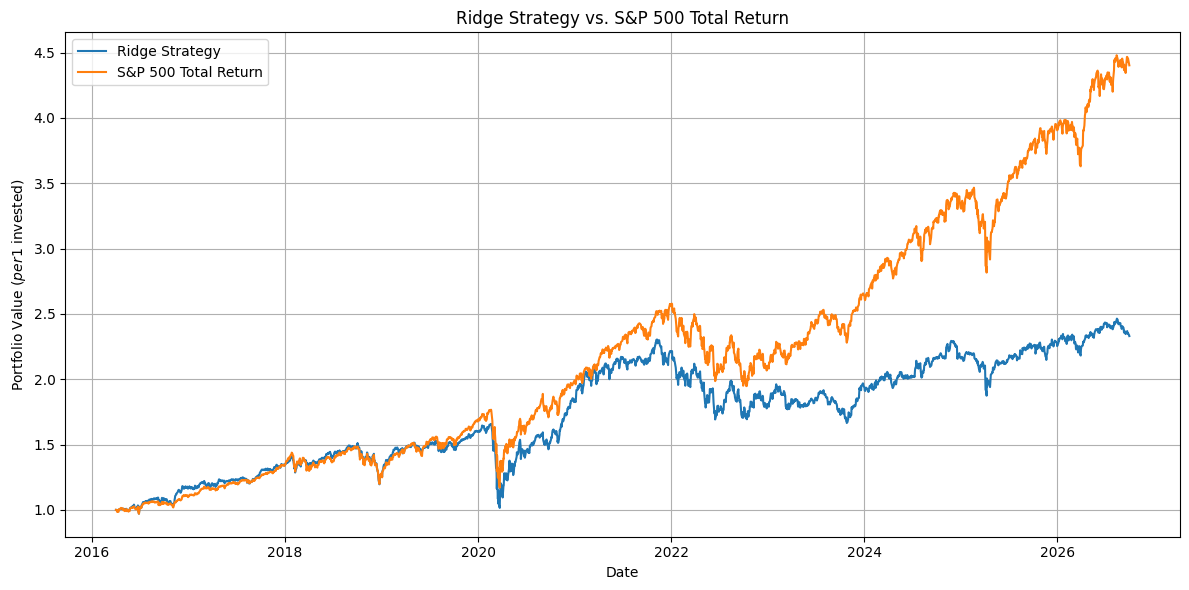

Outperformance in final dollars: $-2,072,450.23
Total transaction fees: $62,605.15
Open lots at test end: 3531


In [103]:
# Calculate final performance and risk statistics

initial_value = 1_000_000
risk_free_rate = 0.02
trading_days_per_year = 252

def calculate_metrics(nav):
    daily_returns = nav.pct_change().dropna()
    years = (nav.index[-1] - nav.index[0]).days / 365.25

    cagr = (nav.iloc[-1] / initial_value) ** (1 / years) - 1
    drawdown = nav / nav.cummax() - 1
    daily_rf = (1 + risk_free_rate) ** (1 / trading_days_per_year) - 1
    excess_returns = daily_returns - daily_rf

    sharpe = (
        excess_returns.mean() / daily_returns.std() * np.sqrt(trading_days_per_year)
        if daily_returns.std() > 0 else np.nan
    )

    return {
        "Final NAV": nav.iloc[-1],
        "Cumulative Return": nav.iloc[-1] / initial_value - 1,
        "CAGR": cagr,
        "Maximum Drawdown": drawdown.min(),
        "Daily Sharpe (2% RF)": sharpe
    }

strategy_metrics = calculate_metrics(backtest_results["strategy_nav"])
benchmark_metrics = calculate_metrics(backtest_results["benchmark_nav"])

performance_comparison = pd.DataFrame({
    "Ridge Strategy": strategy_metrics,
    "S&P 500 Total Return": benchmark_metrics
})

display(performance_comparison.style.format({
    "Ridge Strategy": "{:,.4f}",
    "S&P 500 Total Return": "{:,.4f}"
}))

# Plot cumulative portfolio growth
plt.figure(figsize=(12, 6))
plt.plot(
    backtest_results.index,
    backtest_results["strategy_nav"] / initial_value,
    label="Ridge Strategy"
)
plt.plot(
    backtest_results.index,
    backtest_results["benchmark_nav"] / initial_value,
    label="S&P 500 Total Return"
)
plt.title("Ridge Strategy vs. S&P 500 Total Return")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($ per $1 invested)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Outperformance in final dollars: ${:,.2f}".format(
    strategy_metrics["Final NAV"] - benchmark_metrics["Final NAV"]
))
print("Total transaction fees: ${:,.2f}".format(oms.total_fees))
print("Open lots at test end:", len(oms.lots))

In [104]:
# Audit trade execution, cash accounting, and 90-day holding periods

buy_fills = fills[fills["side"] == "BUY"]
sell_fills = fills[fills["side"] == "SELL"]

# Every buy should execute at the next trading session after its signal
date_array = np.array(trading_dates, dtype="datetime64[ns]")
expected_positions = np.searchsorted(
    date_array,
    pd.to_datetime(buy_fills["signal_date"]).values,
    side="right"
)
expected_dates = date_array[expected_positions]

# Verify that all open lots are still within their holding periods
open_lot_due_dates = pd.Series(
    [lot.due_date for lot in oms.lots.values()]
)

print("Cash reconciliation:",
      np.isclose(
          oms.initial_cash + fills["cash_change"].sum(),
          oms.cash,
          atol=0.01
      ))

print("Fee reconciliation:",
      np.isclose(fills["fee"].sum(), oms.total_fees, atol=0.01))

print("Buy execution timing correct:",
      np.all(
          pd.to_datetime(buy_fills["date"]).values
          == expected_dates
      ))

print("All sales on or after due date:",
      (pd.to_datetime(sell_fills["date"]) >=
       pd.to_datetime(sell_fills["due_date"])).all())

print("All remaining lots have future due dates:",
      (open_lot_due_dates > last_test_date).all())

print("Buy/sell/open-lot reconciliation:",
      len(buy_fills) - len(sell_fills) == len(oms.lots))

print("Final cash:", round(oms.cash, 2))
print("Final NAV:", round(backtest_results["strategy_nav"].iloc[-1], 2))
print("Total fees:", round(oms.total_fees, 2))

Cash reconciliation: True
Fee reconciliation: True
Buy execution timing correct: True
All sales on or after due date: True
All remaining lots have future due dates: False
Buy/sell/open-lot reconciliation: True
Final cash: 322338.57
Final NAV: 2330296.55
Total fees: 62605.15
